# Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler

import tensorflow as tf
from tensorflow import keras
# from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

from statsmodels.tsa.seasonal import STL
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

# Helper funcitons

In [3]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))


def inverse_signed_log(x):
    return np.sign(x) * np.expm1(np.abs(x))

def get_date_range(df):
    return pd.date_range(
                    start=df["Payindate"].min(),
                    end=df["Payindate"].max(),
                    freq="D"
                    )

# Loading the data

In [4]:
from pathlib import Path

file = Path("sample remit data.csv")
if not file.exists():
    raise FileNotFoundError("remittance_clean.csv not found in the current working directory")

remit_df = pd.read_csv("sample remit data.csv", encoding="utf-16", sep="\t", thousands=",", keep_default_na=False, na_values=[""])
remit_df.head()

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD
0,344100,AE,1/5/2024 12:00:00 AM,1,159.0
1,344100,AE,1/7/2024 12:00:00 AM,2,580.0
2,344100,AE,1/10/2024 12:00:00 AM,1,131.0
3,344100,AE,1/11/2024 12:00:00 AM,1,2536.0
4,344100,AE,1/12/2024 12:00:00 AM,1,341.0


In [5]:
remit_df.shape

(305846, 5)

In [6]:
remit_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 305846 entries, 0 to 305845
Data columns (total 5 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Sendingagentcompanyid  305846 non-null  int64  
 1   Payoutcountrycode      305846 non-null  str    
 2   Payindate              305846 non-null  str    
 3   No of Txn              305846 non-null  int64  
 4   payOutAmtUSD           295428 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 11.7 MB


In [7]:
remit_df.describe()

,Sendingagentcompanyid,No of Txn,payOutAmtUSD
count,305846.000000,305846.000000,2.954280e+05
mean,570439.391831,62.179489,4.660653e+04
std,142272.652397,448.415289,3.137368e+05
min,344100.000000,-46.000000,-8.733561e+06
25%,458100.000000,1.000000,2.620000e+02
50%,512112.000000,2.000000,1.219000e+03
75%,702800.000000,11.000000,9.372250e+03
max,784100.000000,19201.000000,2.097370e+07


In [8]:
remit_df.isnull().sum()

Sendingagentcompanyid        0
Payoutcountrycode            0
Payindate                    0
No of Txn                    0
payOutAmtUSD             10418
dtype: int64

In [9]:
# Checking for duplicates
remit_df[remit_df.duplicated(subset=['Payindate', 'Sendingagentcompanyid', 'Payoutcountrycode'])]

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD


In [10]:
remit_df.groupby('Payoutcountrycode')[['Sendingagentcompanyid','Payoutcountrycode']].value_counts().sort_values(ascending=False)

Payoutcountrycode  Sendingagentcompanyid
AE                 512112                   731
                   480222                   731
                   634212                   731
                   784100                   731
                   414173                   731
                                           ... 
VG                 634008                     1
VC                 512112                     1
AM                 356176                     1
IL                 512112                     1
IS                 344100                     1
Name: count, Length: 1558, dtype: int64

# Preparing the data

## Converting Payindate to datetime

In [11]:
remit_df['Payindate'].dtype

<StringDtype(storage='python', na_value=nan)>

In [12]:
remit_df[['Payindate', 'Time', 'AM']] = remit_df['Payindate'].str.split(' ', expand=True)
remit_df.head()

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD,Time,AM
0,344100,AE,1/5/2024,1,159.0,12:00:00,AM
1,344100,AE,1/7/2024,2,580.0,12:00:00,AM
2,344100,AE,1/10/2024,1,131.0,12:00:00,AM
3,344100,AE,1/11/2024,1,2536.0,12:00:00,AM
4,344100,AE,1/12/2024,1,341.0,12:00:00,AM


In [13]:
print(remit_df['Time'].unique())
print(remit_df['AM'].unique())

<StringArray>
['12:00:00']
Length: 1, dtype: str
<StringArray>
['AM']
Length: 1, dtype: str


In [14]:
remit_df.drop(columns=['Time', 'AM'], inplace=True)
remit_df.head()

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD
0,344100,AE,1/5/2024,1,159.0
1,344100,AE,1/7/2024,2,580.0
2,344100,AE,1/10/2024,1,131.0
3,344100,AE,1/11/2024,1,2536.0
4,344100,AE,1/12/2024,1,341.0


In [15]:
remit_df['Payindate'] = pd.to_datetime(remit_df['Payindate'], dayfirst=False)
remit_df.head()

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD
0,344100,AE,2024-01-05,1,159.0
1,344100,AE,2024-01-07,2,580.0
2,344100,AE,2024-01-10,1,131.0
3,344100,AE,2024-01-11,1,2536.0
4,344100,AE,2024-01-12,1,341.0


## Sectioning data to top 5 companies and countries

In [16]:
# Top 10 most active countries
remit_df.groupby('Payoutcountrycode')['No of Txn'].sum().sort_values(ascending=False)[:10]


Payoutcountrycode
IN    7465152
PK    4365246
PH    1357068
NP     980055
AE     930598
BD     850299
EG     392331
LK     316410
ID     304352
UG     251609
Name: No of Txn, dtype: int64

In [17]:
# Top 10 most active companies
remit_df.groupby('Sendingagentcompanyid')['No of Txn'].sum().sort_values(ascending=False)[:10]

Sendingagentcompanyid
784100    9438794
702800    4238467
414173    1452309
512112    1019774
480222     824563
634008     761155
634212     574591
458100     446086
356176     103776
344100      70791
Name: No of Txn, dtype: int64

In [18]:
# Obtaining gross activity - top active companies in top active countries
top5_countries = remit_df.groupby('Payoutcountrycode')['No of Txn'].sum().sort_values(ascending=False)[:5].index
top5_country_df = remit_df[remit_df['Payoutcountrycode'].isin(top5_countries)]
top5_countries

Index(['IN', 'PK', 'PH', 'NP', 'AE'], dtype='str', name='Payoutcountrycode')

In [19]:
top5_companies = top5_country_df.groupby('Sendingagentcompanyid')['No of Txn'].sum().sort_values(ascending=False)[:5].index
df = top5_country_df[top5_country_df['Sendingagentcompanyid'].isin(top5_companies)]
top5_companies

Index([784100, 702800, 414173, 512112, 480222], dtype='int64', name='Sendingagentcompanyid')

In [20]:
df

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD
16560,414173,AE,2024-01-01,31,29724.0
16561,414173,AE,2024-01-02,250,55757.0
16562,414173,AE,2024-01-03,155,-16005.0
16563,414173,AE,2024-01-04,71,75213.0
16564,414173,AE,2024-01-05,48,18594.0
...,...,...,...,...,...
288988,784100,PK,2025-12-27,2298,980494.0
288989,784100,PK,2025-12-28,2624,1052598.0
288990,784100,PK,2025-12-29,2732,1265657.0
288991,784100,PK,2025-12-30,2819,1297320.0


In [21]:
df.groupby('Payoutcountrycode')[['Sendingagentcompanyid']].value_counts().sort_values()


Payoutcountrycode  Sendingagentcompanyid
AE                 702800                   241
NP                 702800                   722
PH                 702800                   728
AE                 480222                   731
                   512112                   731
IN                 414173                   731
                   784100                   731
AE                 414173                   731
IN                 480222                   731
                   702800                   731
NP                 784100                   731
IN                 512112                   731
NP                 512112                   731
                   480222                   731
                   414173                   731
AE                 784100                   731
PH                 512112                   731
                   480222                   731
                   414173                   731
                   784100                   731

In [22]:
corridor_summary = df.groupby(['Sendingagentcompanyid', 'Payoutcountrycode']).agg(
    first_date   = ('Payindate', 'min'),
    last_date    = ('Payindate', 'max'),
    observations = ('Payindate', 'count'),
    unique_dates = ('Payindate', 'nunique')
).reset_index()

corridor_summary.sort_values('observations')

,Sendingagentcompanyid,Payoutcountrycode,first_date,last_date,observations,unique_dates
15,702800,AE,2024-09-11,2025-12-31,241,241
17,702800,NP,2024-01-01,2025-12-31,722,722
18,702800,PH,2024-01-02,2025-12-31,728,728
0,414173,AE,2024-01-01,2025-12-31,731,731
4,414173,PK,2024-01-01,2025-12-31,731,731
5,480222,AE,2024-01-01,2025-12-31,731,731
2,414173,NP,2024-01-01,2025-12-31,731,731
1,414173,IN,2024-01-01,2025-12-31,731,731
7,480222,NP,2024-01-01,2025-12-31,731,731
8,480222,PH,2024-01-01,2025-12-31,731,731


## Handling null values

In [23]:
df_null = df[df.isnull().any(axis=1)]
df_null

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD
223209,702800,AE,2024-09-11,1,NaN
223210,702800,AE,2024-09-12,1,NaN
223211,702800,AE,2024-09-18,1,NaN
223212,702800,AE,2024-09-24,1,NaN
223215,702800,AE,2024-09-30,1,NaN
...,...,...,...,...,...
237801,702800,PH,2024-05-25,6,NaN
237808,702800,PH,2024-06-01,18,NaN
237820,702800,PH,2024-06-13,11,NaN
237823,702800,PH,2024-06-16,8,NaN


In [24]:
df_null['Sendingagentcompanyid'].unique()

array([702800])

In [25]:
df_null['Payoutcountrycode'].unique()


<StringArray>
['AE', 'NP', 'PH']
Length: 3, dtype: str

In [26]:
df_null.groupby('Payoutcountrycode')['Payoutcountrycode'].value_counts()

Payoutcountrycode
AE    45
NP    12
PH    42
Name: count, dtype: int64

Filling the null values with interpolation - using company country pair

In [27]:
df['payOutAmtUSD'] = df.groupby(['Sendingagentcompanyid', 'Payoutcountrycode'])['payOutAmtUSD'].transform(lambda s: s.interpolate(method='linear', limit=2).bfill().ffill())

df[df['payOutAmtUSD'].isna()]

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD


In [28]:
df[df.isnull().any(axis=1)]

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD


## Reindexing

In [29]:
def reindex_group(g):
    g = g.set_index('Payindate').sort_index()
    full_range = pd.date_range(g.index.min(), g.index.max(), freq='D')
    g = g.reindex(full_range)
    g.index.name = 'Payindate'
    return g

In [30]:
# filling in missing dates in the dataset if there are
df = (
    df.groupby(['Sendingagentcompanyid', 'Payoutcountrycode'], group_keys=True)
            .apply(reindex_group)
)
df = df.drop(columns=['Sendingagentcompanyid', 'Payoutcountrycode'], errors='ignore').reset_index()
df['No of Txn'] = df['No of Txn'].fillna(0)
df['payOutAmtUSD'] = df['payOutAmtUSD'].fillna(0)


In [31]:
df[df.isnull().any(axis=1)]

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD


In [32]:
print(df.shape)


(18020, 5)


In [33]:
df.groupby('Payoutcountrycode')[['Sendingagentcompanyid','Payoutcountrycode']].value_counts()


Payoutcountrycode  Sendingagentcompanyid
AE                 414173                   731
                   784100                   731
                   480222                   731
                   512112                   731
                   702800                   477
IN                 414173                   731
                   784100                   731
                   480222                   731
                   702800                   731
                   512112                   731
NP                 784100                   731
                   702800                   731
                   512112                   731
                   480222                   731
                   414173                   731
PH                 512112                   731
                   480222                   731
                   414173                   731
                   784100                   731
                   702800                   730

In [34]:
df.head()

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD
0,414173,AE,2024-01-01,31.0,29724.0
1,414173,AE,2024-01-02,250.0,55757.0
2,414173,AE,2024-01-03,155.0,-16005.0
3,414173,AE,2024-01-04,71.0,75213.0
4,414173,AE,2024-01-05,48.0,18594.0


In [35]:
# Saving data for feature engineering 
df.to_csv("remittance_sliced.csv", index=False)

# Exploratory data analysis

In [36]:
corridor_summary = df.groupby(['Sendingagentcompanyid', 'Payoutcountrycode']).agg(
    first_date   = ('Payindate', 'min'),
    last_date    = ('Payindate', 'max'),
    observations = ('Payindate', 'count'),
    unique_dates = ('Payindate', 'nunique')
).reset_index()

corridor_summary.sort_values('observations')

,Sendingagentcompanyid,Payoutcountrycode,first_date,last_date,observations,unique_dates
15,702800,AE,2024-09-11,2025-12-31,477,477
18,702800,PH,2024-01-02,2025-12-31,730,730
2,414173,NP,2024-01-01,2025-12-31,731,731
0,414173,AE,2024-01-01,2025-12-31,731,731
4,414173,PK,2024-01-01,2025-12-31,731,731
5,480222,AE,2024-01-01,2025-12-31,731,731
6,480222,IN,2024-01-01,2025-12-31,731,731
1,414173,IN,2024-01-01,2025-12-31,731,731
7,480222,NP,2024-01-01,2025-12-31,731,731
8,480222,PH,2024-01-01,2025-12-31,731,731


In [37]:
corridor_summary['expected_days'] = (corridor_summary['last_date'] - corridor_summary['first_date']).dt.days + 1
corridor_summary['missing_dates'] = corridor_summary['expected_days'] - corridor_summary['unique_dates']

corridor_summary[
    ['Sendingagentcompanyid',
     'Payoutcountrycode',
     'observations',
     'first_date',
     'last_date',
     'expected_days',
     'missing_dates'
    ]
].sort_values('missing_dates', ascending=False)

,Sendingagentcompanyid,Payoutcountrycode,observations,first_date,last_date,expected_days,missing_dates
0,414173,AE,731,2024-01-01,2025-12-31,731,0
1,414173,IN,731,2024-01-01,2025-12-31,731,0
2,414173,NP,731,2024-01-01,2025-12-31,731,0
3,414173,PH,731,2024-01-01,2025-12-31,731,0
4,414173,PK,731,2024-01-01,2025-12-31,731,0
5,480222,AE,731,2024-01-01,2025-12-31,731,0
6,480222,IN,731,2024-01-01,2025-12-31,731,0
7,480222,NP,731,2024-01-01,2025-12-31,731,0
8,480222,PH,731,2024-01-01,2025-12-31,731,0
9,480222,PK,731,2024-01-01,2025-12-31,731,0


## Aggregate analysis

In [38]:
daily = df.groupby('Payindate')[['No of Txn', 'payOutAmtUSD']].sum()
daily

,No of Txn,payOutAmtUSD
Payindate,,
2024-01-01,8733.0,5161921.0
2024-01-02,11294.0,5697969.0
2024-01-03,11288.0,7565191.0
2024-01-04,10504.0,6722872.0
2024-01-05,9655.0,5288846.0
...,...,...
2025-12-27,26770.0,11701895.0
2025-12-28,24922.0,9866004.0
2025-12-29,31505.0,16497361.0


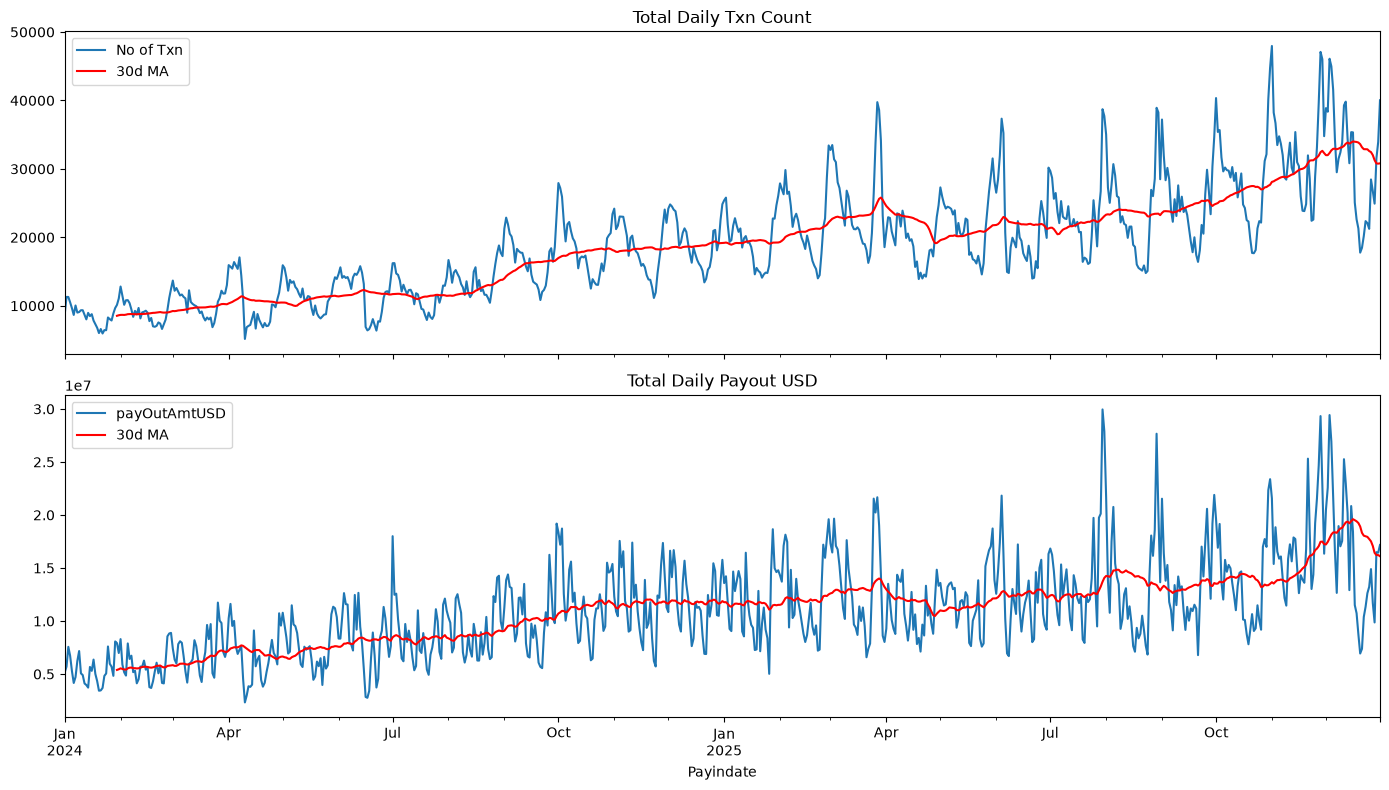

In [39]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
daily['No of Txn'].plot(ax=ax[0], title='Total Daily Txn Count')
daily['No of Txn'].rolling(30).mean().plot(ax=ax[0], color='red', label='30d MA')
daily['payOutAmtUSD'].plot(ax=ax[1], title='Total Daily Payout USD')
daily['payOutAmtUSD'].rolling(30).mean().plot(ax=ax[1], color='red', label='30d MA')
ax[0].legend(); ax[1].legend(); plt.tight_layout()

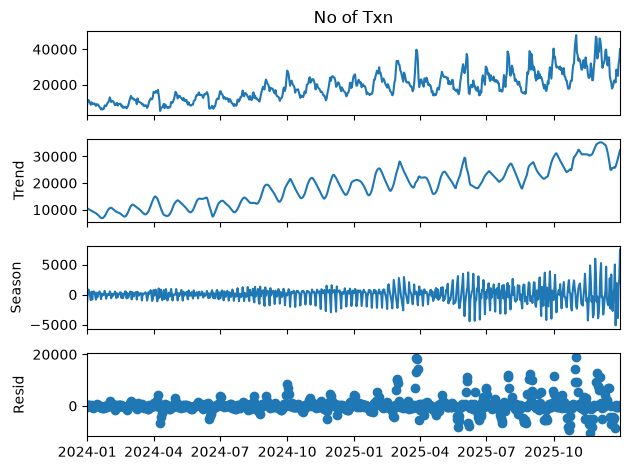

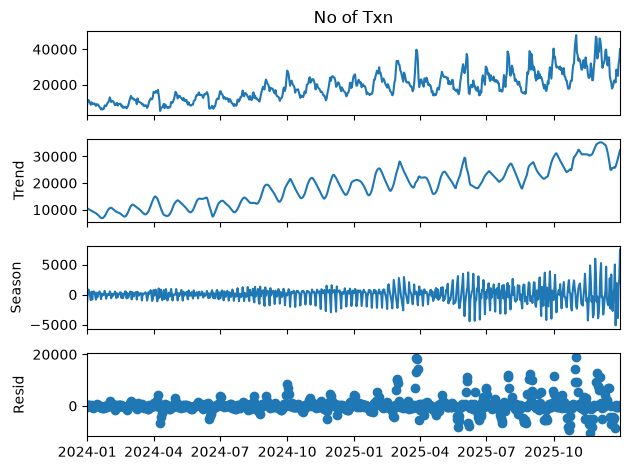

In [40]:
s = daily['No of Txn']
res = STL(s, period=7, robust=True).fit()  # period=7 for weekly seasonality
res.plot()

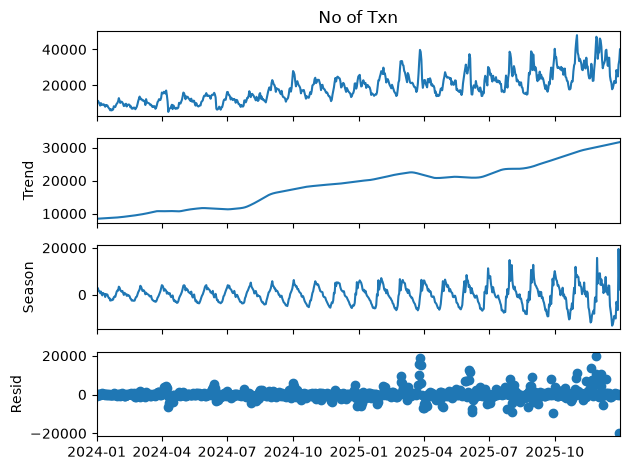

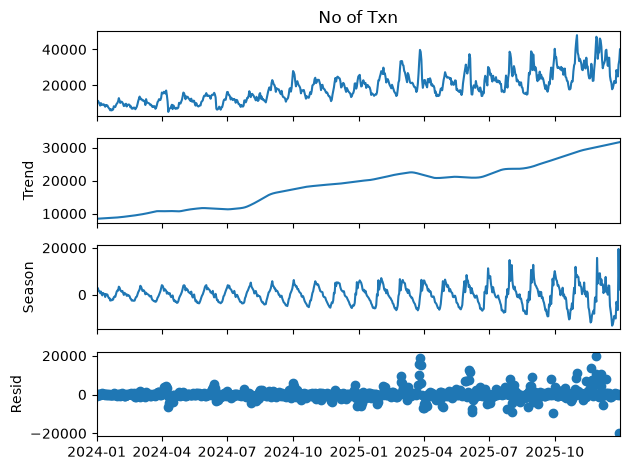

In [41]:
s = daily['No of Txn']
res = STL(s, period=30, robust=True).fit()
res.plot()

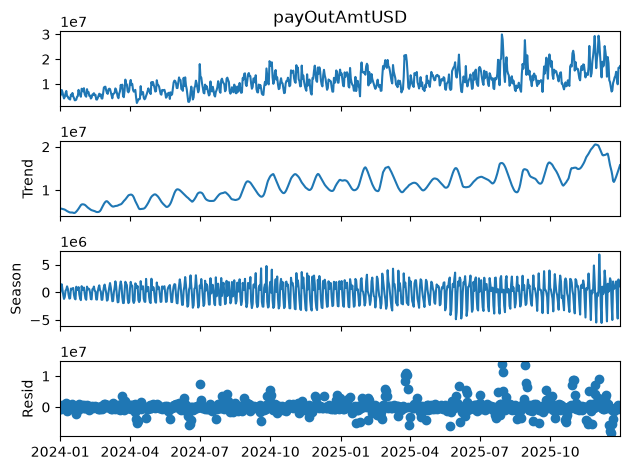

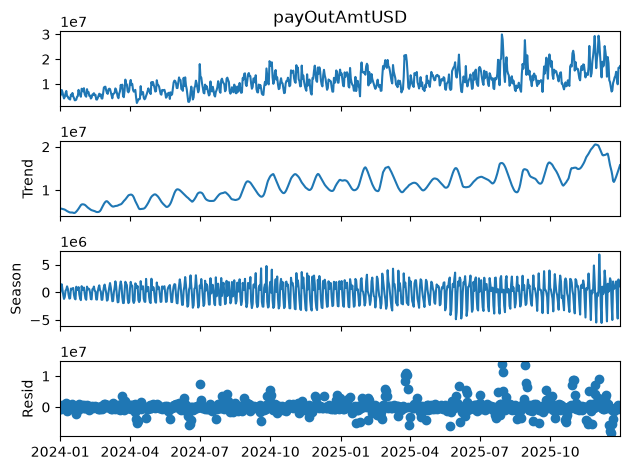

In [42]:
s = daily['payOutAmtUSD']
res = STL(s, period=7, robust=True).fit()
res.plot()

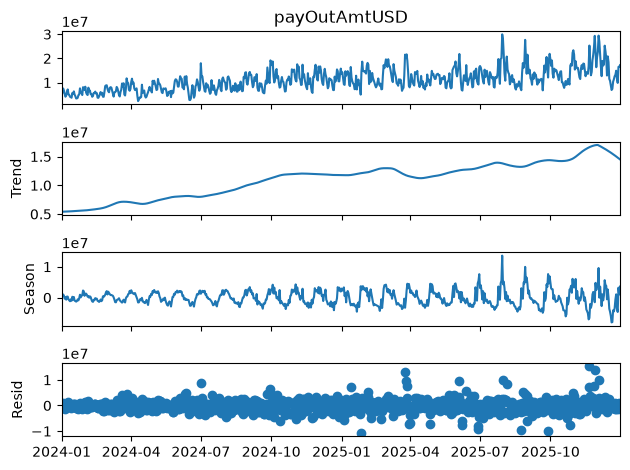

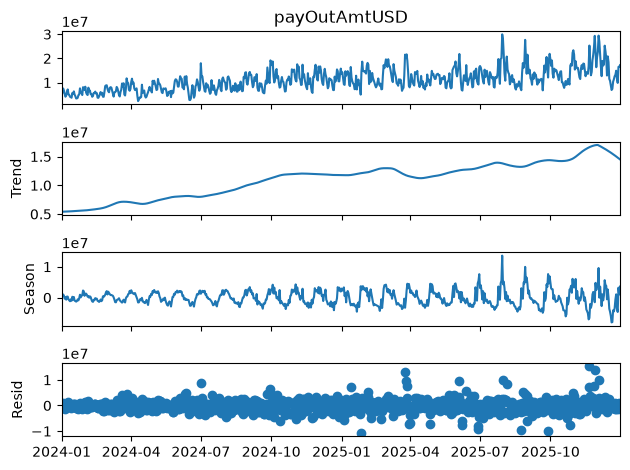

In [43]:
s = daily['payOutAmtUSD']
res = STL(s, period=30, robust=True).fit()
res.plot()

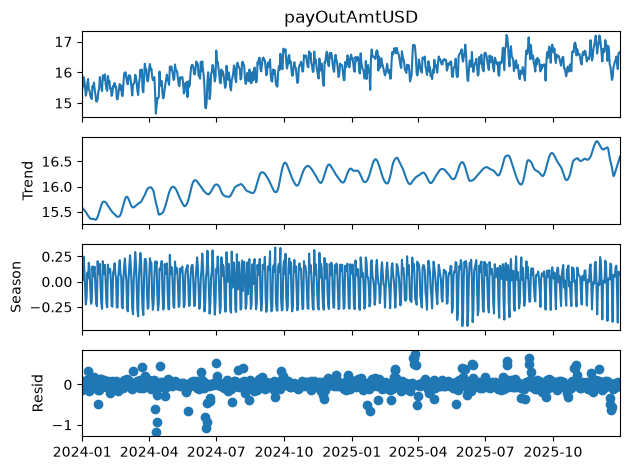

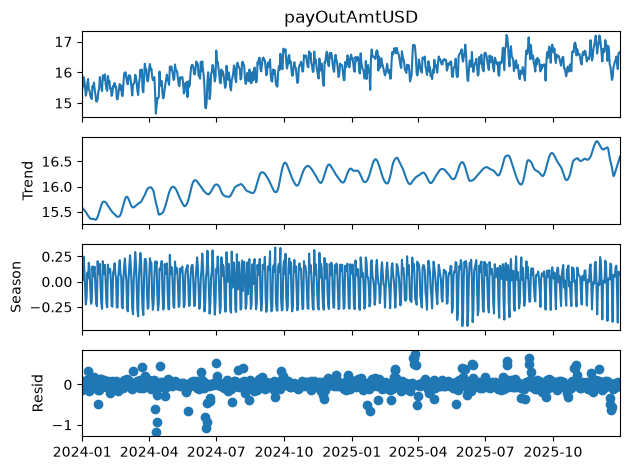

In [44]:
# Running STL on signed log amt
s = np.sign(daily['payOutAmtUSD']) * np.log1p(np.abs(daily['payOutAmtUSD']))
res = STL(s, period=7, robust=True).fit()
res.plot()

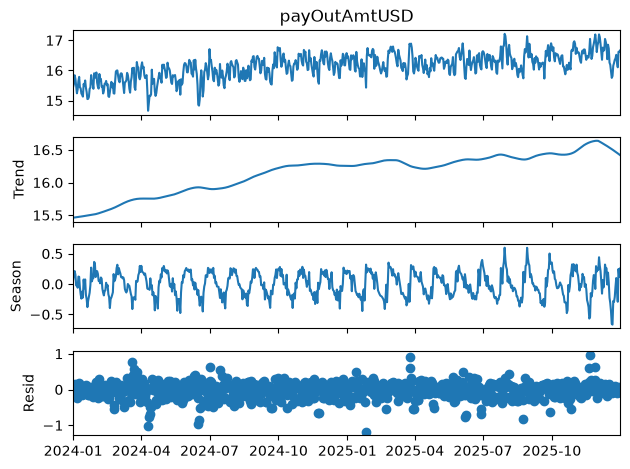

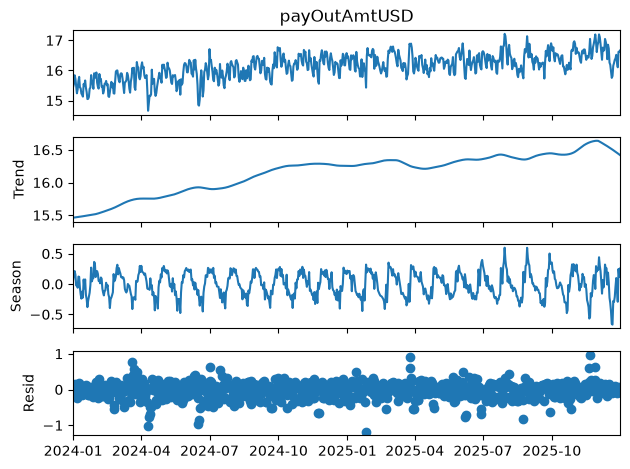

In [45]:
# Running STL on signed log amt
s = np.sign(daily['payOutAmtUSD']) * np.log1p(np.abs(daily['payOutAmtUSD']))
res = STL(s, period=30, robust=True).fit()
res.plot()

## Corridor analysis

In [46]:
corridor_stats = df.groupby(['Sendingagentcompanyid', 'Payoutcountrycode']).agg(
    amount_mean     = ('payOutAmtUSD', 'mean'),
        amount_median   = ('payOutAmtUSD', 'median'),
        amount_std      = ('payOutAmtUSD', 'std'),
        amount_min      = ('payOutAmtUSD', 'min'),
        amount_max      = ('payOutAmtUSD', 'max'),

    txn_mean    = ('No of Txn', 'mean'),
    txn_median  = ('No of Txn', 'median'),
    txn_std     = ('No of Txn', 'std'),
    txn_min     = ('No of Txn', 'min'),
    txn_max     = ('No of Txn', 'max'),
    total_txn   = ('No of Txn', 'sum'),

    n_days          = ('Payindate', 'nunique'),
).sort_values('amount_mean', ascending=False).reset_index()

corridor_stats

,Sendingagentcompanyid,Payoutcountrycode,amount_mean,amount_median,amount_std,amount_min,amount_max,txn_mean,txn_median,txn_std,txn_min,txn_max,total_txn,n_days
0,784100,IN,4.455583e+06,3827407.0,2.631197e+06,832947.0,20973703.0,5233.417237,4167.0,3366.195558,1090.0,18127.0,3825628.0,731
1,784100,PK,1.158117e+06,1148379.0,3.444468e+05,123271.0,2489124.0,3118.324213,3045.0,882.435919,429.0,6866.0,2279495.0,731
2,702800,PK,9.121202e+05,182343.0,1.121979e+06,-928.0,4862540.0,2132.474692,484.0,2496.102206,1.0,11440.0,1558839.0,731
3,784100,AE,9.052561e+05,696573.0,6.448544e+05,110319.0,6901224.0,1036.616963,1033.0,172.018392,303.0,1801.0,757767.0,731
4,414173,IN,8.931085e+05,772928.0,5.503490e+05,-1772466.0,3378188.0,983.608755,933.0,355.735164,407.0,2122.0,719018.0,731
5,702800,IN,6.432697e+05,164115.0,1.237853e+06,-2269.0,8833169.0,2613.140903,594.0,3732.395105,17.0,19201.0,1910206.0,731
6,512112,AE,3.650615e+05,351100.0,1.959923e+05,12815.0,1040500.0,150.227086,149.0,42.323579,20.0,282.0,109816.0,731
7,480222,IN,3.113761e+05,288091.0,1.250681e+05,110917.0,926124.0,492.549932,455.0,169.901490,221.0,1148.0,360054.0,731
8,784100,PH,2.435390e+05,203217.0,1.206551e+05,78125.0,739370.0,620.854993,532.0,285.370398,267.0,1740.0,453845.0,731
9,784100,NP,1.972919e+05,184981.0,9.273632e+04,52378.0,715602.0,588.440492,530.0,288.254725,169.0,2298.0,430150.0,731


In [47]:
corridor_stats.describe()

,Sendingagentcompanyid,amount_mean,amount_median,amount_std,amount_min,amount_max,txn_mean,txn_median,txn_std,txn_min,txn_max,total_txn,n_days
count,25.000000,2.500000e+01,2.500000e+01,2.500000e+01,2.500000e+01,2.500000e+01,25.000000,25.000000,25.000000,25.000000,25.00000,2.500000e+01,25.00000
mean,578681.400000,4.425705e+05,3.421256e+05,3.234481e+05,-2.840955e+05,2.311130e+06,754.960113,544.800000,510.844007,134.920000,2874.20000,5.516363e+05,720.80000
std,143462.379089,9.037318e+05,7.781214e+05,5.858950e+05,1.128826e+06,4.496007e+06,1252.343904,975.346605,1044.948754,237.973199,5366.65883,9.156093e+05,50.79206
min,414173.000000,8.944461e+03,0.000000e+00,5.413458e+03,-5.191983e+06,2.916800e+04,13.439124,0.000000,3.796545,-2.000000,25.00000,9.824000e+03,477.00000
25%,480222.000000,3.914192e+04,3.177100e+04,2.230451e+04,-1.651200e+04,1.502430e+05,104.986320,96.000000,42.323579,6.000000,282.00000,7.674500e+04,731.00000
50%,512112.000000,1.304634e+05,8.192200e+04,9.273632e+04,-3.000000e+01,7.156020e+05,219.432285,202.000000,82.972242,23.000000,687.00000,1.604050e+05,731.00000
75%,702800.000000,3.650615e+05,2.032170e+05,3.444468e+05,1.281500e+04,2.382164e+06,620.854993,530.000000,285.370398,169.000000,1801.00000,4.538450e+05,731.00000
max,784100.000000,4.455583e+06,3.827407e+06,2.631197e+06,8.329470e+05,2.097370e+07,5233.417237,4167.000000,3732.395105,1090.000000,19201.00000,3.825628e+06,731.00000


In [48]:
df[['No of Txn', 'payOutAmtUSD']].corr()

,No of Txn,payOutAmtUSD
No of Txn,1.000000,0.858343
payOutAmtUSD,0.858343,1.000000


In [49]:
df.groupby(['Sendingagentcompanyid','Payoutcountrycode',])[['No of Txn', 'payOutAmtUSD']].corr()


No of Txn  payOutAmtUSD
Sendingagentcompanyid Payoutcountrycode                                      
414173                AE                No of Txn      1.000000      0.107553
                                        payOutAmtUSD   0.107553      1.000000
                      IN                No of Txn      1.000000      0.651301
                                        payOutAmtUSD   0.651301      1.000000
                      NP                No of Txn      1.000000      0.694321
                                        payOutAmtUSD   0.694321      1.000000
                      PH                No of Txn      1.000000      0.279038
                                        payOutAmtUSD   0.279038      1.000000
                      PK                No of Txn      1.000000      0.564866
                                        payOutAmtUSD   0.564866      1.000000
480222                AE                No of Txn      1.000000      0.550740
                                        payOutAmtUSD   0.550740      1.000000
                      IN                No of Txn      1.000000      0.874345
                                        payOutAmtUSD   0.874345      1.000000
                      NP                No of Txn      1.000000      0.908491
                                        payOutAmtUSD   0.908491      1.000000
                      PH                No of Txn      1.000000      0.896986
                                        payOutAmtUSD   0.896986      1.000000
                      PK                No of Txn      1.000000      0.872096
                                        payOutAmtUSD   0.872096      1.000000
512112                AE                No of Txn      1.000000      0.642626
                                        payOutAmtUSD   0.642626      1.000000
                      IN                No of Txn      1.000000      0.849414
                                        payOutAmtUSD   0.849414      1.000000
                      NP                No of Txn      1.000000      0.971785
                                        payOutAmtUSD   0.971785      1.000000
                      PH                No of Txn      1.000000      0.886845
                                        payOutAmtUSD   0.886845      1.000000
                      PK                No of Txn      1.000000      0.943738
                                        payOutAmtUSD   0.943738      1.000000
702800                AE                No of Txn      1.000000      0.957143
                                        payOutAmtUSD   0.957143      1.000000
                      IN                No of Txn      1.000000      0.857267
                                        payOutAmtUSD   0.857267      1.000000
                      NP                No of Txn      1.000000      0.866062
                                        payOutAmtUSD   0.866062      1.000000
                      PH                No of Txn      1.000000      0.907564
                                        payOutAmtUSD   0.907564      1.000000
                      PK                No of Txn      1.000000      0.993361
                                        payOutAmtUSD   0.993361      1.000000
784100                AE                No of Txn      1.000000      0.130109
                                        payOutAmtUSD   0.130109      1.000000
                      IN                No of Txn      1.000000      0.880104
                                        payOutAmtUSD   0.880104      1.000000
                      NP                No of Txn      1.000000      0.978603
                                        payOutAmtUSD   0.978603      1.000000
                      PH                No of Txn      1.000000      0.899548
                                        payOutAmtUSD   0.899548      1.000000
                      PK                No of Txn      1.000000      0.906939
                                        payOutAmtUSD   0.906939      1.00000

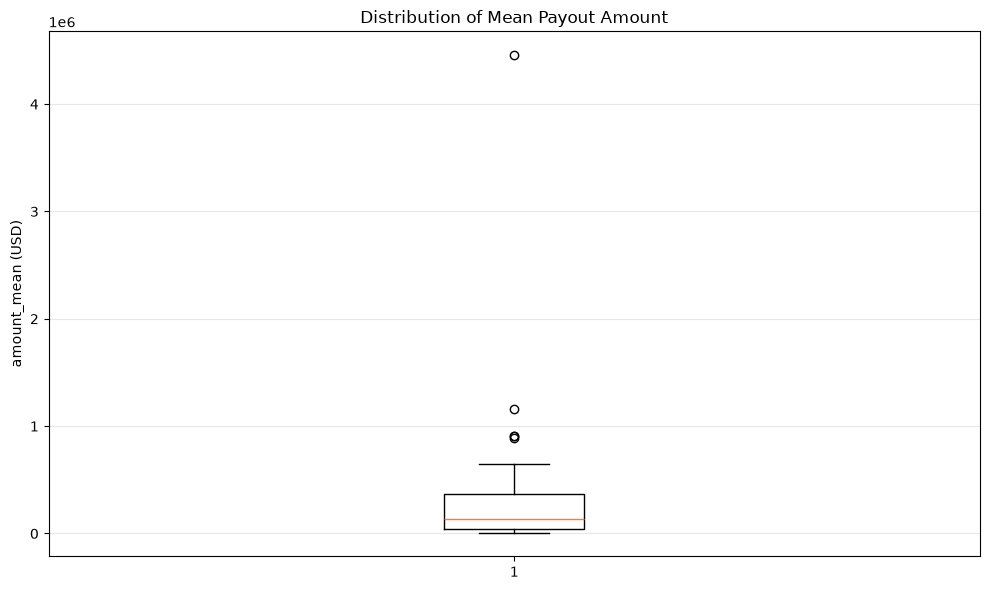

In [50]:
plt.figure(figsize=(10, 6))
plt.boxplot(corridor_stats['amount_mean'])
plt.title('Distribution of Mean Payout Amount')
plt.ylabel('amount_mean (USD)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
# for (company, country), group in df.groupby(['Sendingagentcompanyid', 'Payoutcountrycode']):
#     plt.figure(figsize=(12, 4))
    
#     plt.plot(
#         group['Payindate'],
#         group['payOutAmtUSD']
#     )
    
#     plt.title(f'Payout Amount — Company {company} → {country}')
#     plt.xlabel('Date')
#     plt.ylabel('payOutAmtUSD')
#     plt.xticks(rotation=45)
#     plt.tight_layout()
#     plt.show()

In [52]:
corridor_max = corridor_stats.iloc[0]
corridor_min = corridor_stats.iloc[12]
corridor_mid = corridor_stats.iloc[24]
 

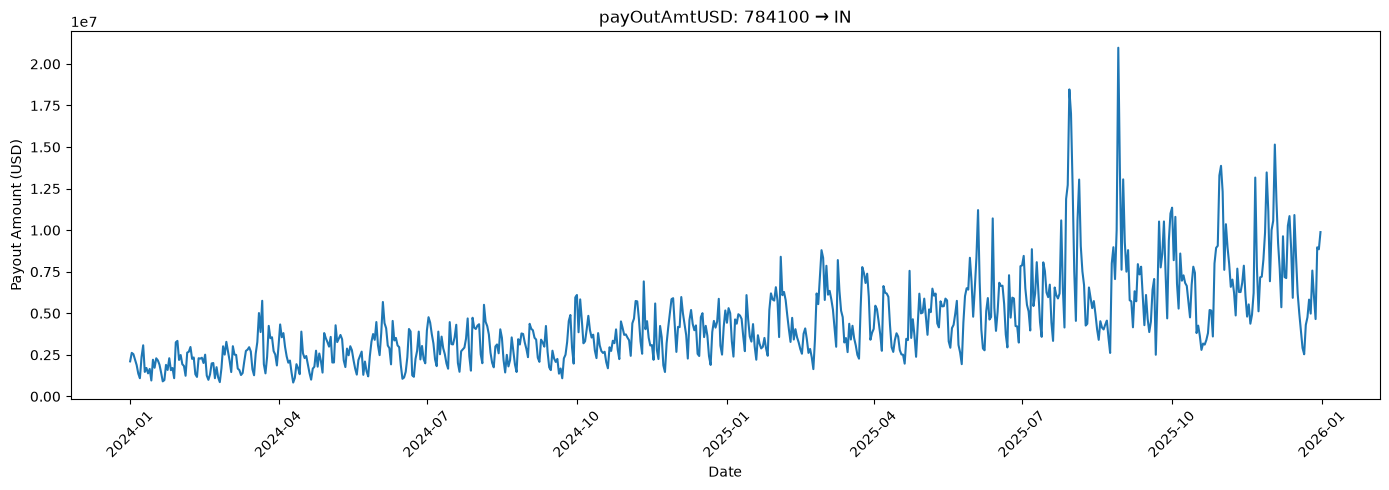

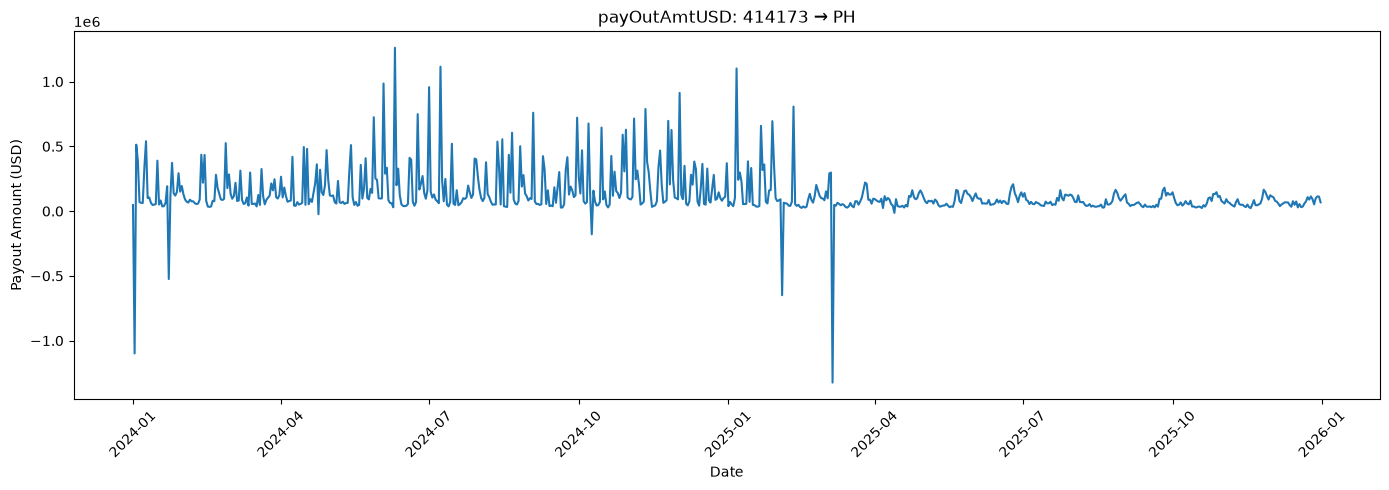

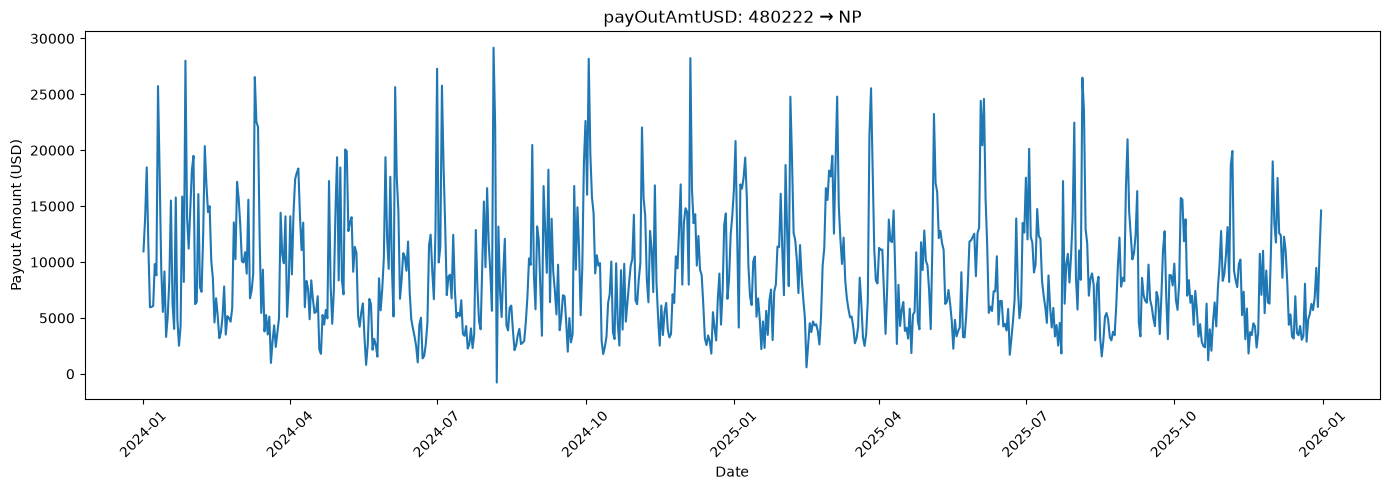

In [53]:
corridors = [
    (784100, 'IN'),
    (414173, 'PH'),
    (480222, 'NP')
]

for company, country in corridors:

    data = df[ 
        ( df['Payoutcountrycode'] == country ) & (df['Sendingagentcompanyid'] == company) 
        ].sort_values('Payindate')

    plt.figure(figsize=(14, 5))
    plt.plot( data['Payindate'], data['payOutAmtUSD'] )

    plt.title(f'payOutAmtUSD: {company} → {country}')
    plt.xlabel('Date')
    plt.ylabel('Payout Amount (USD)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()



In [54]:
df['payOutAmtUSD'].corr(df['No of Txn'])

np.float64(0.858343061005539)

In [55]:
lags = [1, 2, 3, 7, 14, 21, 28]
results = []

for (company, country), group in df.groupby(['Sendingagentcompanyid', 'Payoutcountrycode']):

    temp = group.sort_values('Payindate').copy()

    for lag in lags:
        corr = temp['payOutAmtUSD'].corr( temp['payOutAmtUSD'].shift(lag))

        results.append({
        'company': company,
        'country': country,
        'lag': lag,
        'correlation': corr
        })

lag_corr = pd.DataFrame(results)
lag_corr

,company,country,lag,correlation
0,414173,AE,1,-0.025910
1,414173,AE,2,0.016862
2,414173,AE,3,-0.016915
3,414173,AE,7,0.247612
4,414173,AE,14,0.274614
...,...,...,...,...
170,784100,PK,3,0.603397
171,784100,PK,7,0.376720
172,784100,PK,14,0.181324
173,784100,PK,21,0.249665


In [56]:
lag_corr.pivot(
    index=['company', 'country'],
    columns='lag',
    values='correlation'
)

lag                    1         2         3         7         14        21  \
company country                                                               
414173  AE      -0.025910  0.016862 -0.016915  0.247612  0.274614  0.231851   
        IN       0.464553  0.236711  0.088936  0.316184  0.091369  0.118294   
        NP       0.553420  0.332445  0.192816  0.268437 -0.056133  0.151156   
        PH       0.105366  0.045428  0.010586  0.312080  0.265199  0.358598   
        PK       0.418346  0.342775  0.184225  0.382710  0.260453  0.289840   
480222  AE       0.298621  0.257360  0.177461  0.279000  0.351221  0.339566   
        IN       0.696500  0.463310  0.354040  0.197939 -0.193206 -0.022247   
        NP       0.562661  0.380509  0.338518  0.122169 -0.364194 -0.051230   
        PH       0.730497  0.560251  0.458894 -0.012351 -0.432142 -0.248022   
        PK       0.524916  0.253588  0.198034  0.184603 -0.006089  0.022459   
512112  AE       0.309684  0.003470 -0.194640  0.474265  0.455734  0.506827   
        IN       0.645969  0.427608  0.336430  0.196924 -0.213999 -0.030761   
        NP       0.746179  0.537291  0.388460  0.058272 -0.474309 -0.175814   
        PH       0.687540  0.561628  0.441968  0.052272 -0.476995 -0.164067   
        PK       0.730226  0.525853  0.434631  0.253764 -0.008711  0.140067   
702800  AE       0.893687  0.870538  0.850099  0.896674  0.832568  0.817972   
        IN       0.924652  0.840926  0.802437  0.843467  0.734754  0.630990   
        NP       0.835260  0.729767  0.618135  0.393007 -0.021848  0.206695   
        PH       0.751141  0.673643  0.634375  0.721237  0.618174  0.630041   
        PK       0.961703  0.922218  0.887776  0.865143  0.801383  0.792467   
784100  AE       0.225464  0.164066  0.125462  0.208004  0.149302  0.219082   
        IN       0.780201  0.638263  0.607084  0.577886  0.479847  0.497730   
        NP       0.740003  0.532007  0.433957  0.198866  0.206248  0.140095   
        PH       0.831248  0.682201  0.552689 -0.011346 -0.474059 -0.275506   
        PK       0.891354  0.736136  0.603397  0.376720  0.181324  0.249665   

lag                    28  
company country            
414173  AE       0.162088  
        IN       0.427328  
        NP       0.459898  
        PH       0.344204  
        PK       0.292849  
480222  AE       0.214016  
        IN       0.583072  
        NP       0.503043  
        PH       0.580773  
        PK       0.330444  
512112  AE       0.502410  
        IN       0.467387  
        NP       0.506439  
        PH       0.550756  
        PK       0.434977  
702800  AE       0.806507  
        IN       0.533498  
        NP       0.690750  
        PH       0.727449  
        PK       0.842125  
784100  AE       0.292845  
        IN       0.705385  
        NP       0.665600  
        PH       0.650605  
        PK       0.534299

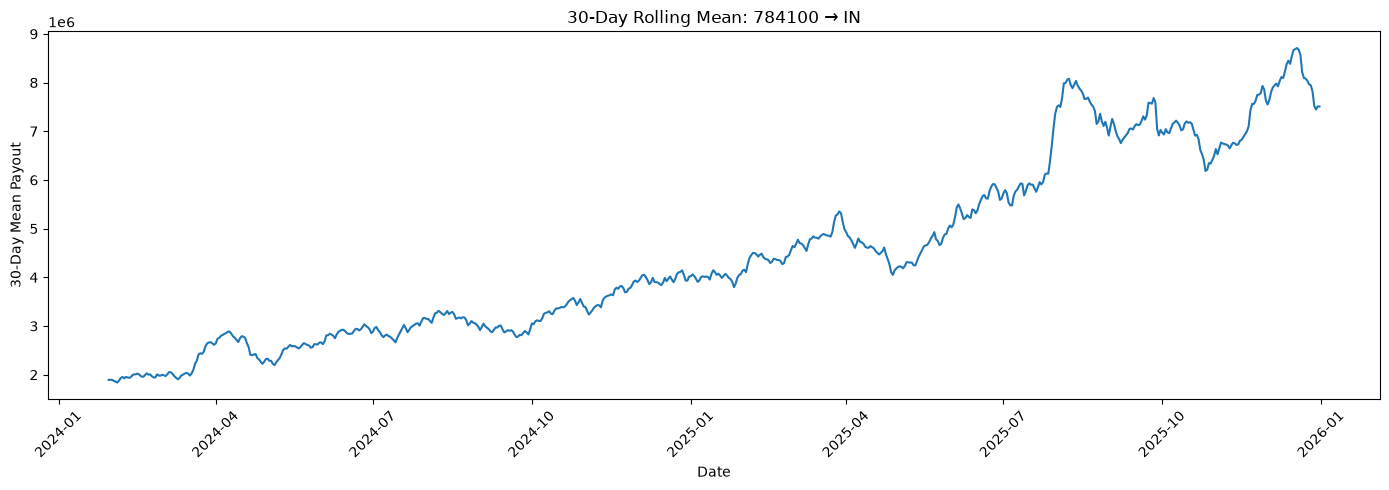

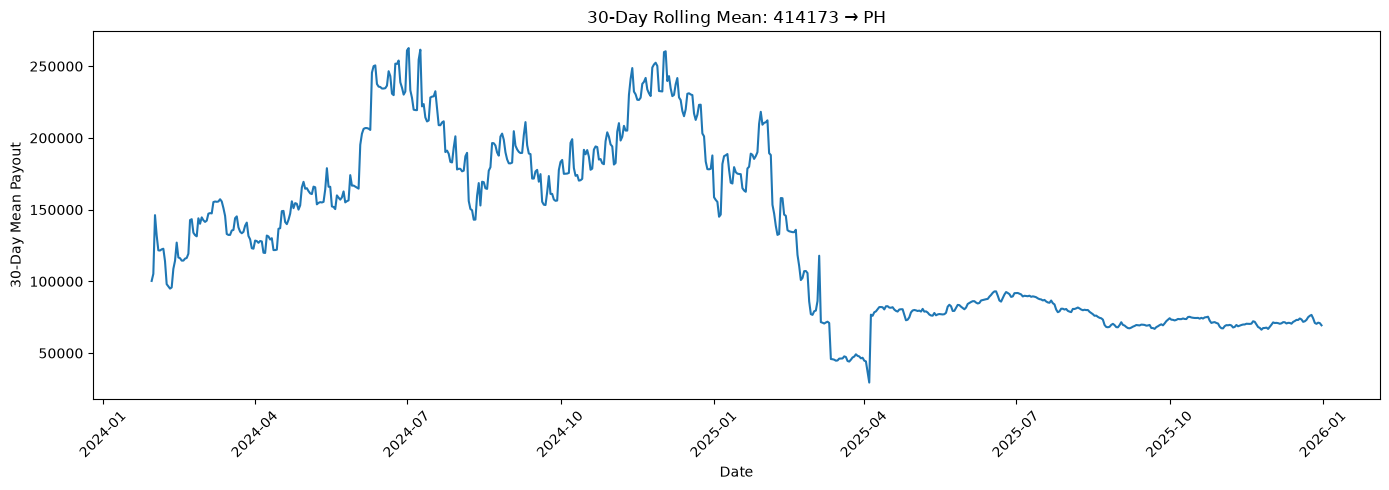

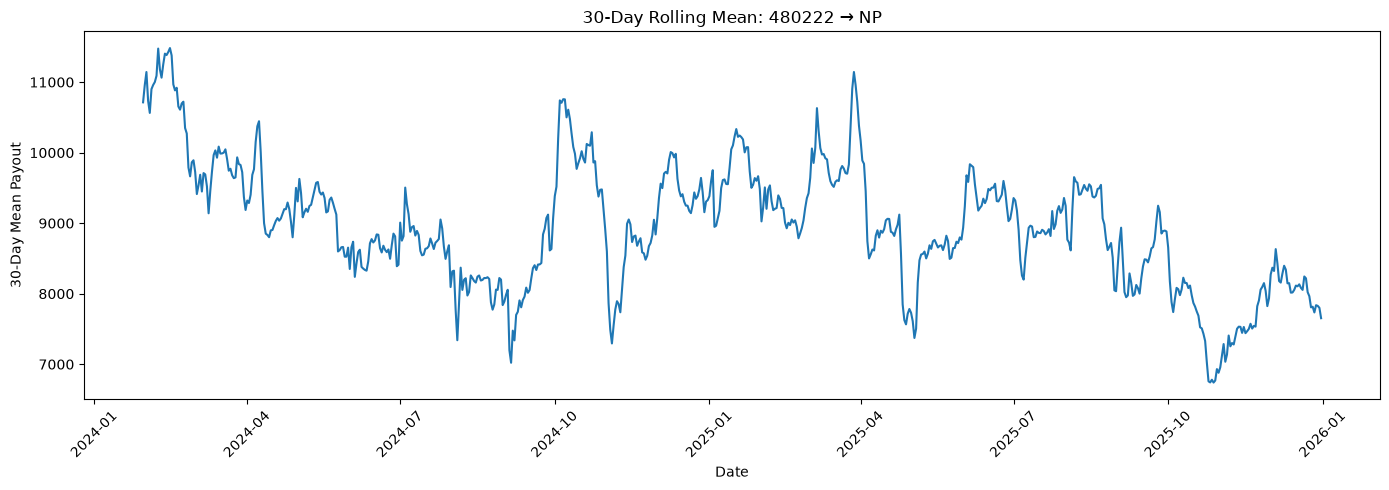

In [57]:
for company, country in corridors:
    
    temp = df[ (df['Sendingagentcompanyid'] == company) & (df['Payoutcountrycode'] == country)
            ].sort_values('Payindate').copy()
    
    temp['rolling_mean_30'] = temp['payOutAmtUSD'].rolling(30).mean()
    
    plt.figure(figsize=(14, 5))
    plt.plot( temp['Payindate'], temp['rolling_mean_30'] )
    plt.title(f'30-Day Rolling Mean: {company} → {country}')
    plt.xlabel('Date')
    plt.ylabel('30-Day Mean Payout')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [58]:
for company, country in corridors:
    
    temp = df[ (df['Sendingagentcompanyid'] == company) & (df['Payoutcountrycode'] == country)
            ].sort_values('Payindate').copy()

    print(temp['payOutAmtUSD'].diff())

15096          NaN
15097     511082.0
15098     -76498.0
15099    -339486.0
15100    -316879.0
           ...    
15822   -1555489.0
15823   -1360878.0
15824    4315984.0
15825    -119317.0
15826    1034702.0
Name: payOutAmtUSD, Length: 731, dtype: float64
2193          NaN
2194   -1145898.0
2195    1611897.0
2196    -127296.0
2197    -315909.0
          ...    
2919     -40663.0
2920      47316.0
2921      14172.0
2922      -1856.0
2923     -44191.0
Name: payOutAmtUSD, Length: 731, dtype: float64
5117       NaN
5118    2932.0
5119    4588.0
5120   -6891.0
5121   -5622.0
         ...  
5843    1112.0
5844    2673.0
5845   -3498.0
5846    4837.0
5847    3789.0
Name: payOutAmtUSD, Length: 731, dtype: float64


In [59]:
temp = df[
    (df['Sendingagentcompanyid'] == 702800) &
    (df['Payoutcountrycode'] == 'PK')
].sort_values('Payindate').copy()

temp['amount_diff'] = temp['payOutAmtUSD'].diff()
temp['amount_diff_lag7'] = temp['amount_diff'].shift(3)


print(
    temp.head(10)
)

       Sendingagentcompanyid Payoutcountrycode  Payindate  No of Txn  \
13634                 702800                PK 2024-01-01      101.0   
13635                 702800                PK 2024-01-02      144.0   
13636                 702800                PK 2024-01-03      134.0   
13637                 702800                PK 2024-01-04      154.0   
13638                 702800                PK 2024-01-05      159.0   
13639                 702800                PK 2024-01-06       43.0   
13640                 702800                PK 2024-01-07       15.0   
13641                 702800                PK 2024-01-08       29.0   
13642                 702800                PK 2024-01-09       21.0   
13643                 702800                PK 2024-01-10       24.0   

       payOutAmtUSD  amount_diff  amount_diff_lag7  
13634       24656.0          NaN               NaN  
13635       32501.0       7845.0               NaN  
13636       36396.0       3895.0               N

In [60]:
results = []

for (company, country), group in df.groupby(['Sendingagentcompanyid', 'Payoutcountrycode']):

    temp = group.sort_values('Payindate').copy()
    temp['amount_diff'] = temp['payOutAmtUSD'].diff()

    for lag in lags:
        corr = temp['amount_diff'].corr( temp['amount_diff'].shift(lag) )

        results.append({
            'company': company,
            'country': country,
            'lag': lag,
            'correlation': corr
        })

diff_lag_corr = pd.DataFrame(results)

diff_lag_corr.pivot(
    index=['company', 'country'],
    columns='lag',
    values='correlation'
)

lag                    1         2         3         7         14        21  \
company country                                                               
414173  AE      -0.520892  0.037274  0.016133  0.174837  0.234601  0.148525   
        IN      -0.287046 -0.074917 -0.127978  0.286747  0.230596  0.173682   
        NP      -0.252340 -0.090403 -0.125244  0.085692  0.151915  0.262499   
        PH      -0.475920 -0.012836 -0.015510  0.208606  0.121268  0.279104   
        PK      -0.435030  0.071448 -0.075322  0.222208  0.179599  0.231242   
480222  AE      -0.478534  0.019190 -0.051414  0.121328  0.228888  0.158185   
        IN      -0.112990 -0.206383 -0.020009  0.296095  0.239228  0.288438   
        NP      -0.291780 -0.158969  0.054668  0.168732  0.064399  0.154871   
        PH      -0.182519 -0.128651  0.043686  0.024893  0.066529  0.004701   
        PK      -0.214729 -0.227852  0.000729  0.165837  0.112337  0.134804   
512112  AE      -0.278087 -0.078852 -0.124510  0.413698  0.358932  0.447833   
        IN      -0.191807 -0.184449  0.005735  0.254125  0.198025  0.194790   
        NP      -0.090498 -0.118957 -0.069184  0.130056  0.012544  0.009380   
        PH      -0.297707 -0.010183  0.025058  0.087246  0.071077  0.019565   
        PK      -0.121298 -0.209774  0.033613  0.340112  0.287418  0.306179   
702800  AE      -0.380868 -0.017759 -0.058958  0.342493  0.138327  0.119295   
        IN       0.054987 -0.300488 -0.206587  0.351491  0.285915  0.259168   
        NP      -0.179961  0.018167 -0.060223  0.311963  0.117927  0.221321   
        PH      -0.344677 -0.076914 -0.008372  0.648518  0.639698  0.629399   
        PK       0.014665 -0.066558 -0.173148  0.357967  0.290393  0.291978   
784100  AE      -0.460734 -0.013844 -0.009395  0.136545  0.059502  0.161984   
        IN      -0.178736 -0.252545  0.032776  0.393661  0.371443  0.391476   
        NP      -0.099332 -0.210940  0.027663  0.418777  0.471415  0.439602   
        PH      -0.054344 -0.056449 -0.005359  0.028405  0.088354  0.033658   
        PK       0.213141 -0.104678 -0.151971  0.174213  0.142345  0.138199   

lag                    28  
company country            
414173  AE       0.110623  
        IN       0.193015  
        NP       0.153947  
        PH       0.229443  
        PK       0.092653  
480222  AE      -0.007097  
        IN       0.376483  
        NP       0.242560  
        PH       0.235402  
        PK       0.160613  
512112  AE       0.379612  
        IN       0.216507  
        NP       0.104074  
        PH       0.142746  
        PK       0.384901  
702800  AE       0.157555  
        IN       0.188281  
        NP       0.335339  
        PH       0.649789  
        PK       0.490025  
784100  AE       0.128848  
        IN       0.453920  
        NP       0.618302  
        PH       0.214229  
        PK       0.308048

# Date features

In [61]:
df['day_of_week'] = df['Payindate'].dt.dayofweek

weekday_stats = df.groupby(
        ['Sendingagentcompanyid',
         'Payoutcountrycode',
         'day_of_week']
    )['payOutAmtUSD'].agg(['mean', 'median', 'std']).reset_index()

weekday_stats

,Sendingagentcompanyid,Payoutcountrycode,day_of_week,mean,median,std
0,414173,AE,0,3.992782e+05,187110.0,526990.279148
1,414173,AE,1,2.141602e+05,168578.0,359304.199040
2,414173,AE,2,2.856017e+05,181728.0,367525.057124
3,414173,AE,3,1.235433e+05,134423.0,575413.519653
4,414173,AE,4,1.525961e+04,30422.0,180835.073827
...,...,...,...,...,...,...
170,784100,PK,2,1.223255e+06,1215997.0,373631.832866
171,784100,PK,3,1.223592e+06,1192913.5,352722.911928
172,784100,PK,4,1.106925e+06,1126095.0,324424.211016
173,784100,PK,5,1.030636e+06,1030566.5,301144.047050


In [62]:
corridor = df[
    (df['Sendingagentcompanyid'] == 702800) &
    (df['Payoutcountrycode'] == 'PH')
]

corridor.groupby('day_of_week')['payOutAmtUSD'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
day_of_week,,,,
0,104,54502.836538,40918.0,52639.401214
1,105,49480.085714,44937.0,46258.190788
2,105,50916.660000,43673.0,51169.542978
3,104,52597.617949,36853.0,56137.770821
4,104,53712.570513,38600.5,59499.478795
5,104,56553.871795,42250.5,57900.733734
6,104,108490.373397,95129.0,99204.872255


In [63]:
with pd.option_context('display.max_rows', None):
    display(df.groupby(
        ['Sendingagentcompanyid',
         'Payoutcountrycode',
         'day_of_week']
    )['payOutAmtUSD'].agg(['mean', 'median', 'std']))

mean  \
Sendingagentcompanyid Payoutcountrycode day_of_week                 
414173                AE                0            3.992782e+05   
                                        1            2.141602e+05   
                                        2            2.856017e+05   
                                        3            1.235433e+05   
                                        4            1.525961e+04   
                                        5            4.514623e+04   
                                        6            1.622277e+05   
                      IN                0            9.298071e+05   
                                        1            9.946314e+05   
                                        2            1.077049e+06   
                                        3            1.206290e+06   
                                        4            8.271869e+05   
                                        5            5.349682e+05   
                                        6            6.787295e+05   
                      NP                0            4.215356e+04   
                                        1            4.102417e+04   
                                        2            4.732422e+04   
                                        3            4.543725e+04   
                                        4            3.724562e+04   
                                        5            2.875980e+04   
                                        6            3.396948e+04   
                      PH                0            2.518846e+05   
                                        1            1.562129e+05   
                                        2            1.574235e+05   
                                        3            1.327182e+05   
                                        4            7.386200e+04   
                                        5            6.073376e+04   
                                        6            7.873420e+04   
                      PK                0            2.879205e+04   
                                        1            2.699586e+04   
                                        2            2.751710e+04   
                                        3            2.516910e+04   
                                        4            2.045141e+04   
                                        5            1.670594e+04   
                                        6            2.208651e+04   
480222                AE                0            1.164526e+04   
                                        1            1.230200e+04   
                                        2            1.254924e+04   
                                        3            1.173530e+04   
                                        4            6.938587e+03   
                                        5            1.040420e+04   
                                        6            1.005027e+04   
                      IN                0            3.331698e+05   
                                        1            3.332542e+05   
                                        2            3.489819e+05   
                                        3            3.771687e+05   
                                        4            2.671814e+05   
                                        5            2.343189e+05   
                                        6            2.847765e+05   
                      NP                0            8.830390e+03   
                                        1            9.570676e+03   
                                        2            9.578848e+03   
                                        3            1.154044e+04   
                                        4            8.194096e+03   
                                        5            6.407269e+03   
                                        6            8.478481e+03   
                      PH                0            3.9354

In [64]:
def plot_corridor_trends(df, company, country):

    temp = df[(df['Sendingagentcompanyid'] == company) & (df['Payoutcountrycode'] == country)].copy()

    temp = temp.sort_values('Payindate')
    temp = temp.set_index('Payindate')

    # Daily rolling trend
    rolling_30 = temp['payOutAmtUSD'].rolling(30).mean()

    # Weekly
    weekly = temp['payOutAmtUSD'].resample('W').sum()

    # Monthly
    monthly = temp['payOutAmtUSD'].resample('ME').sum()

    # ---- Daily + rolling ----
    # plt.figure(figsize=(14, 5))
    # plt.plot(temp.index, temp['payOutAmtUSD'], alpha=0.3)
    # plt.plot(temp.index, rolling_30)

    # plt.title(f'Daily + 30-Day Rolling Mean: {company} → {country}')
    # plt.xlabel('Date')
    # plt.ylabel('Payout')
    # plt.xticks(rotation=45)
    # plt.tight_layout()
    # plt.show()

    # ---- Weekly ----
    plt.figure(figsize=(14, 5))
    plt.plot(weekly.index, weekly)

    plt.title(f'Weekly Payout Trend: {company} → {country}')
    plt.xlabel('Date')
    plt.ylabel('Weekly Payout')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # ---- Monthly ----
    plt.figure(figsize=(14, 5))
    plt.plot(monthly.index, monthly)

    plt.title(f'Monthly Payout Trend: {company} → {country}')
    plt.xlabel('Date')
    plt.ylabel('Monthly Payout')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

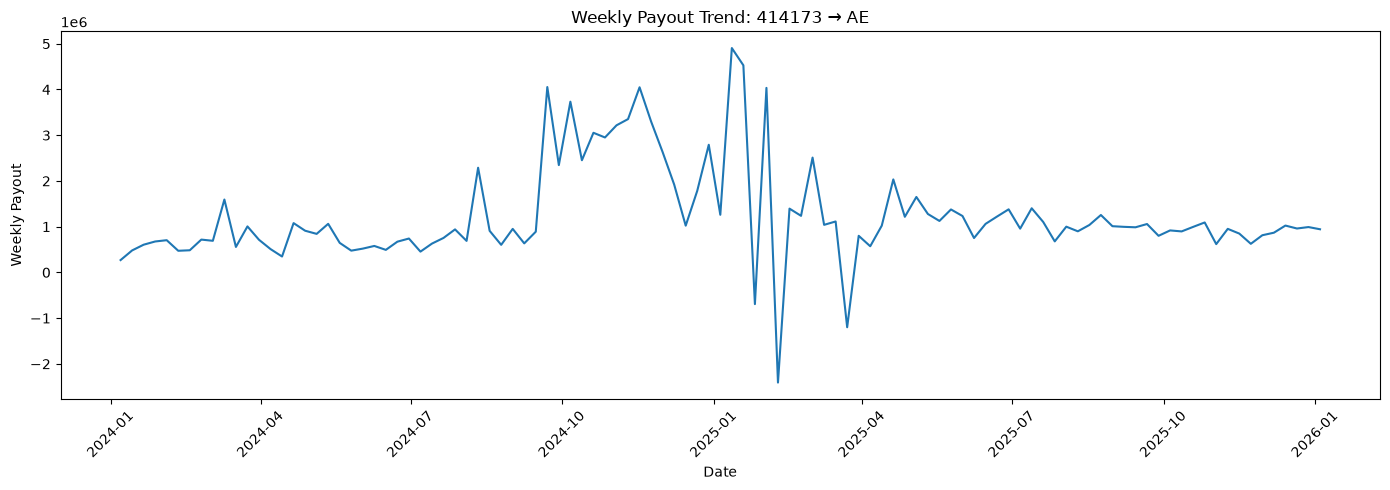

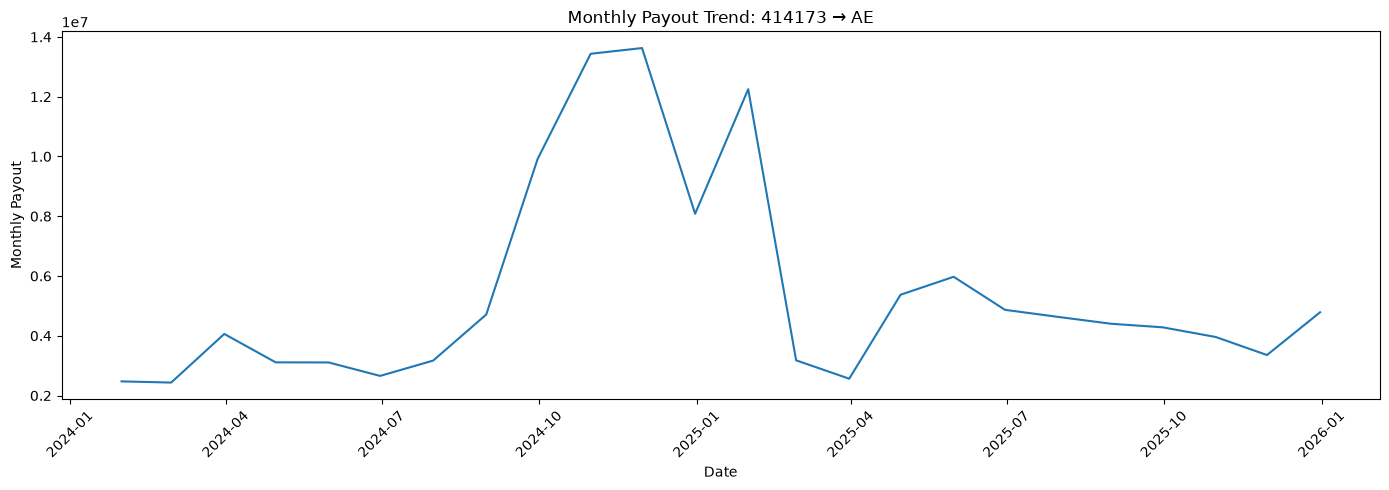

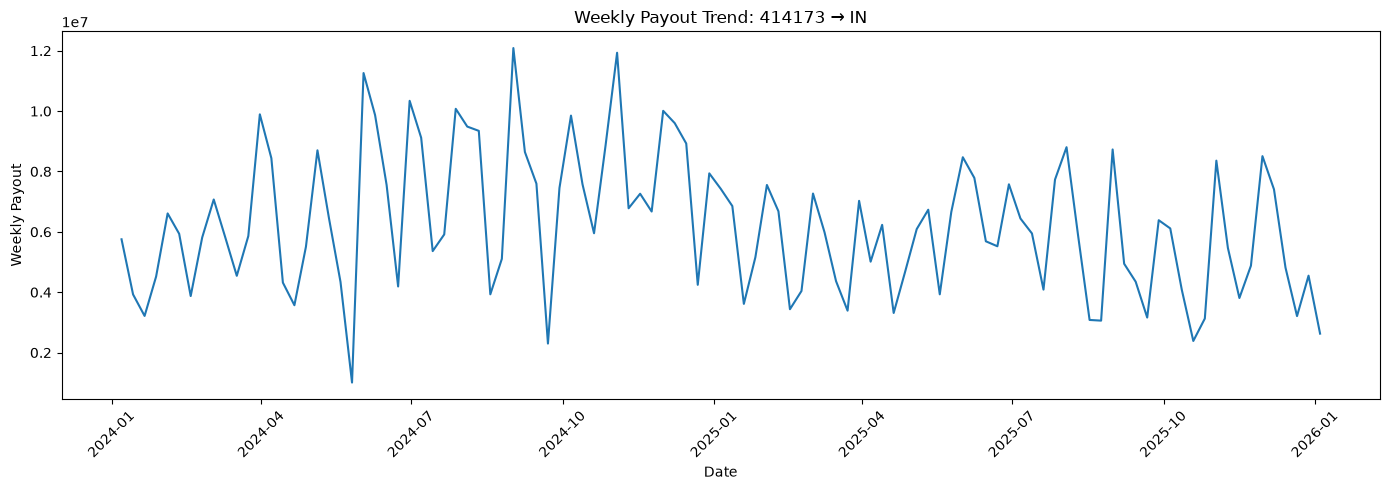

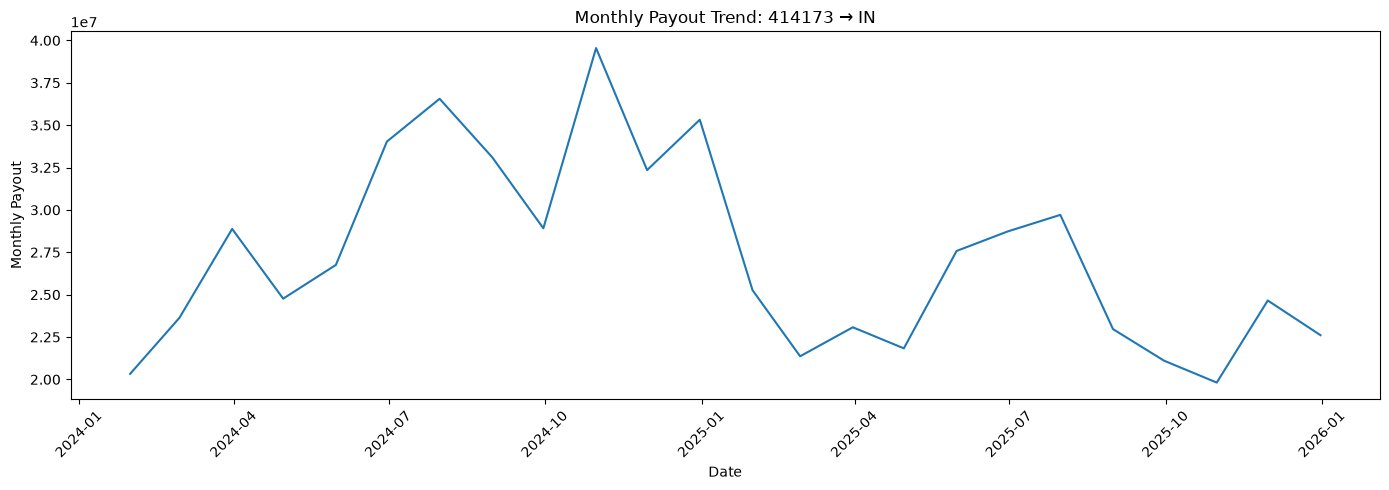

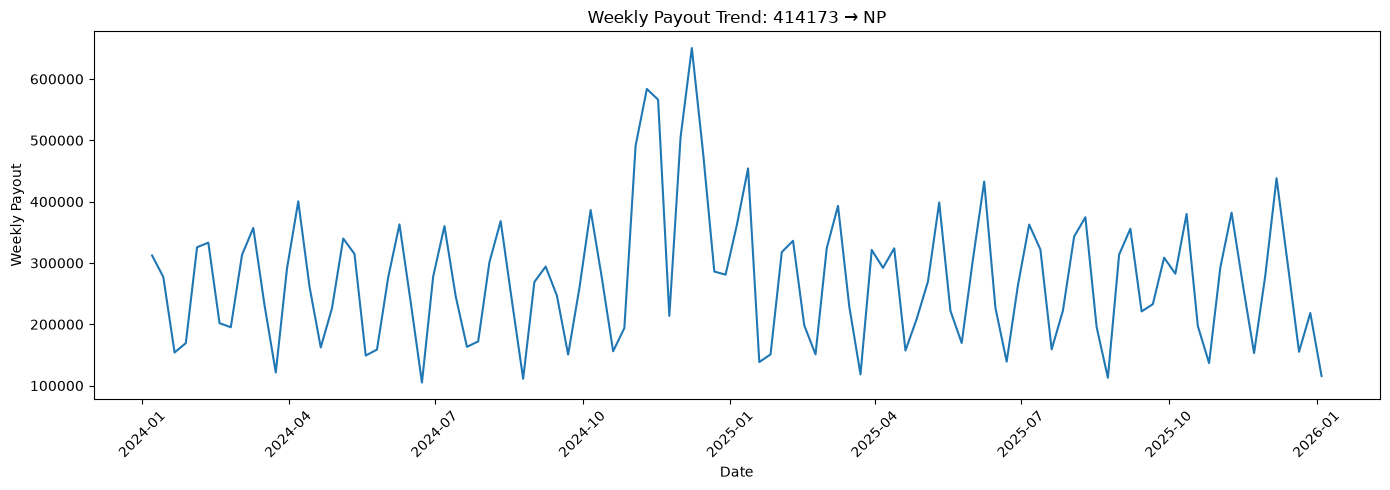

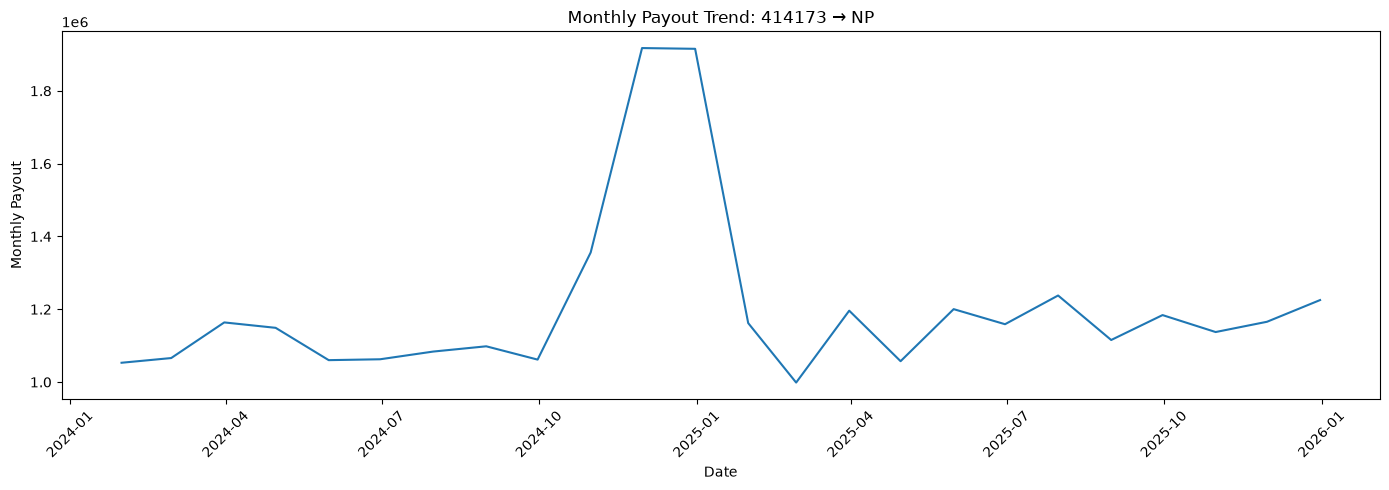

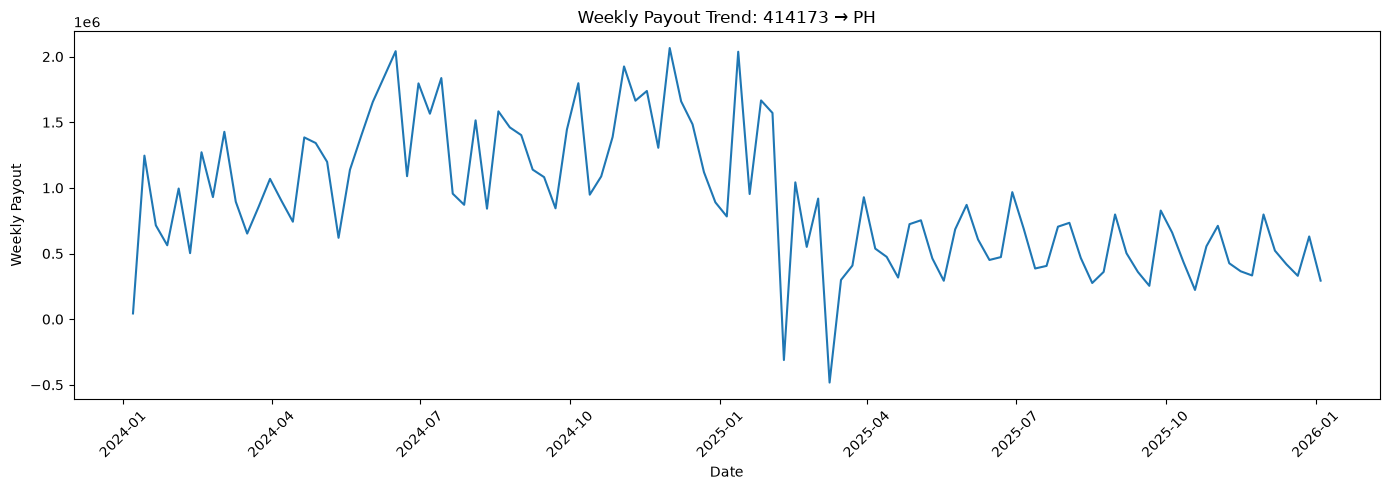

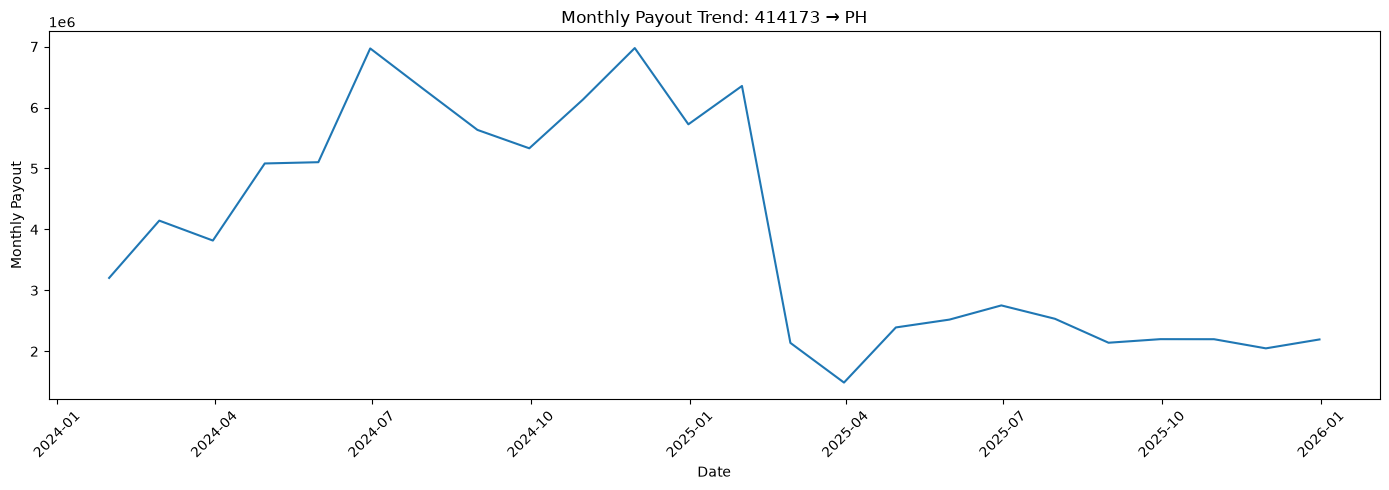

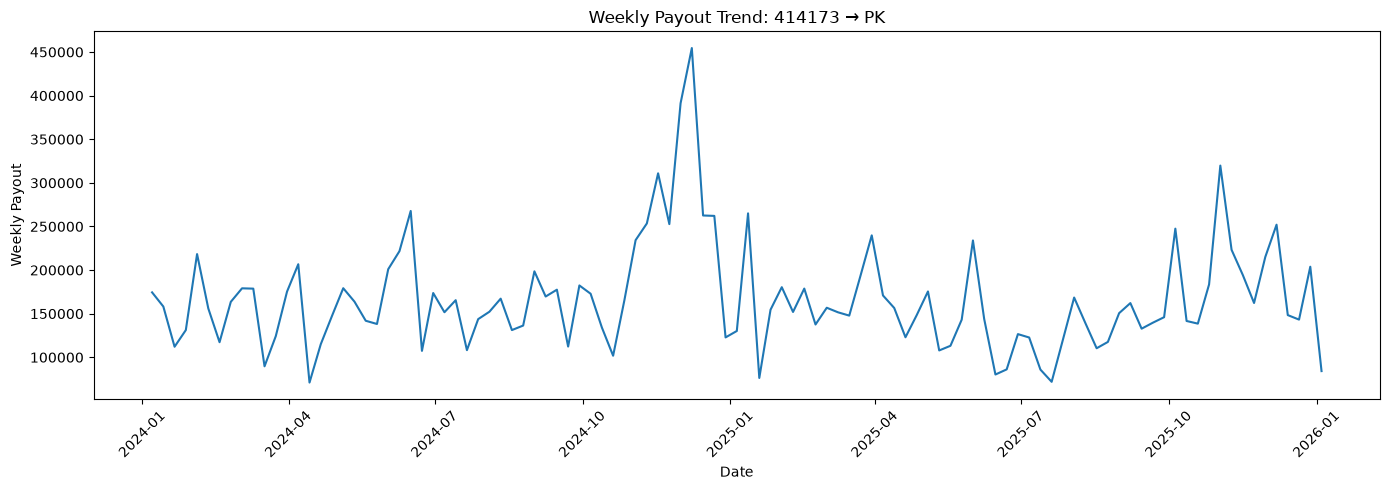

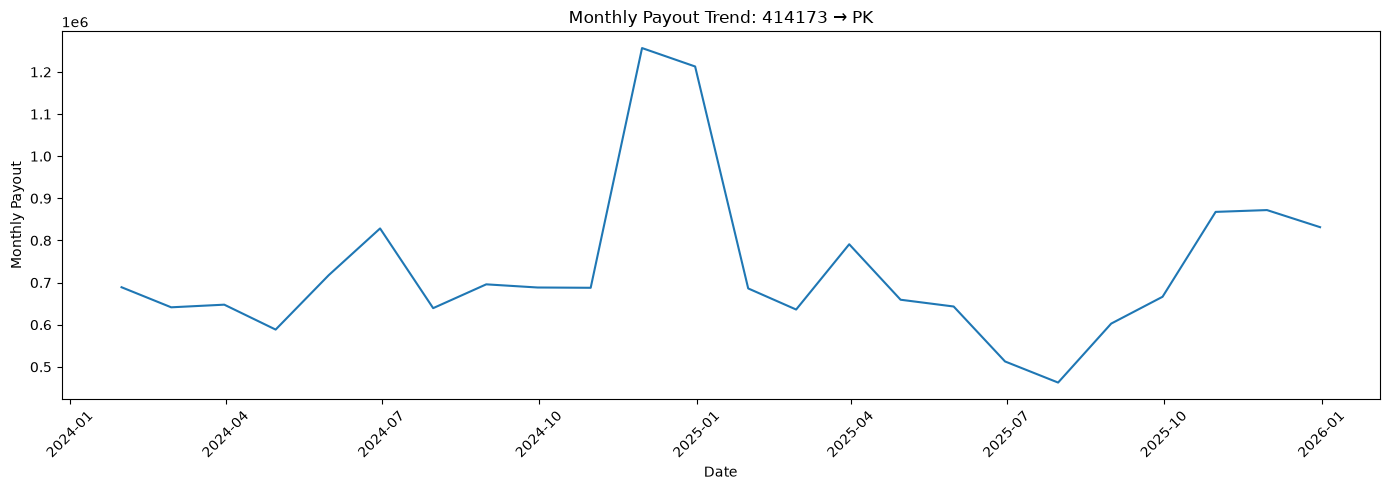

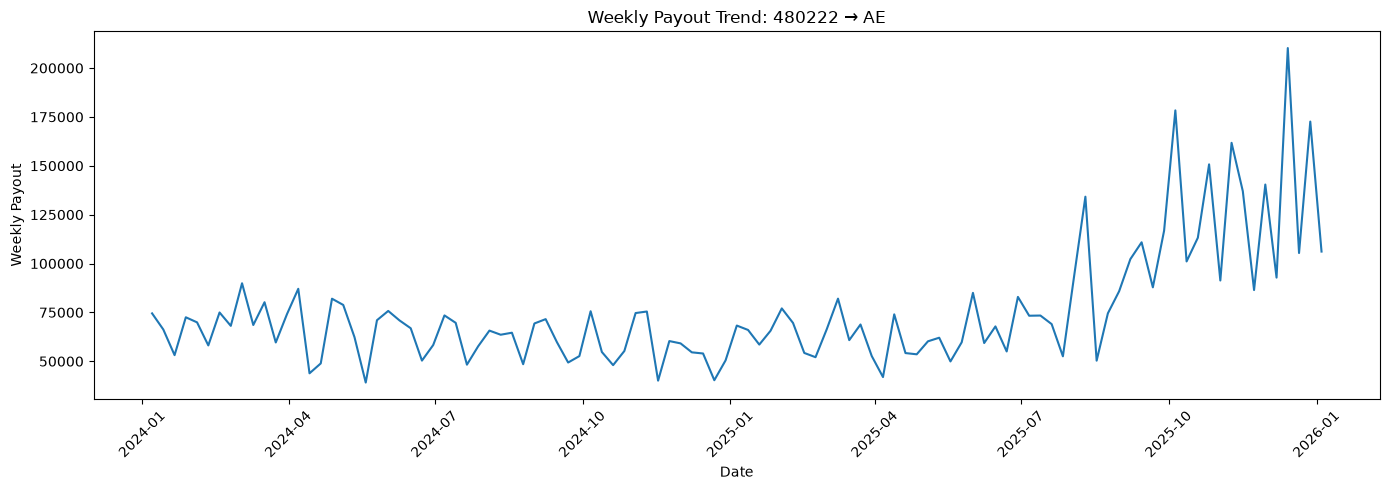

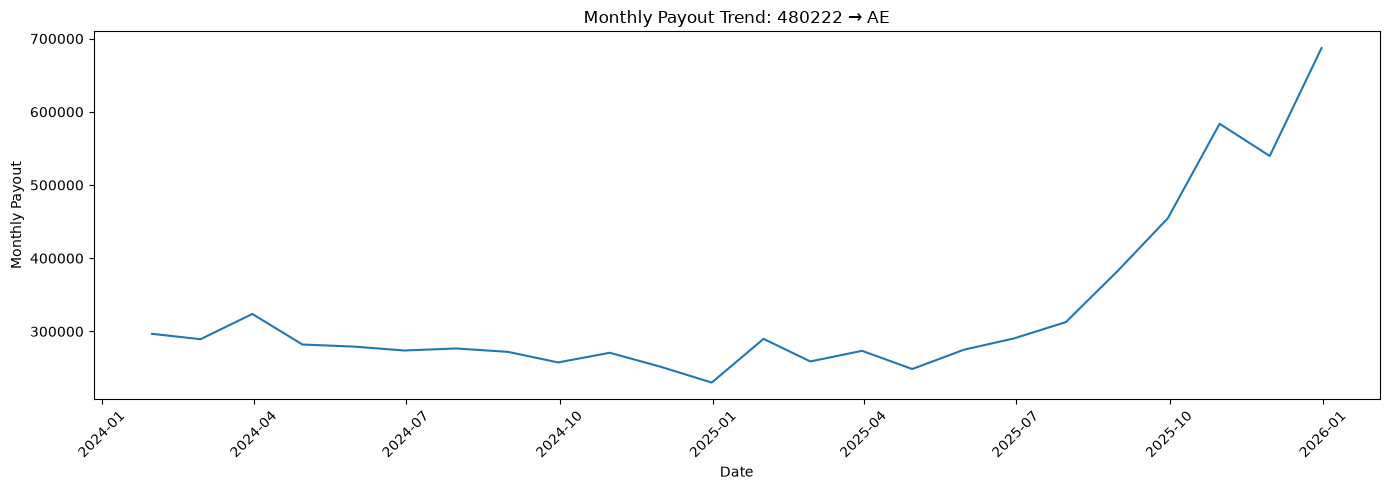

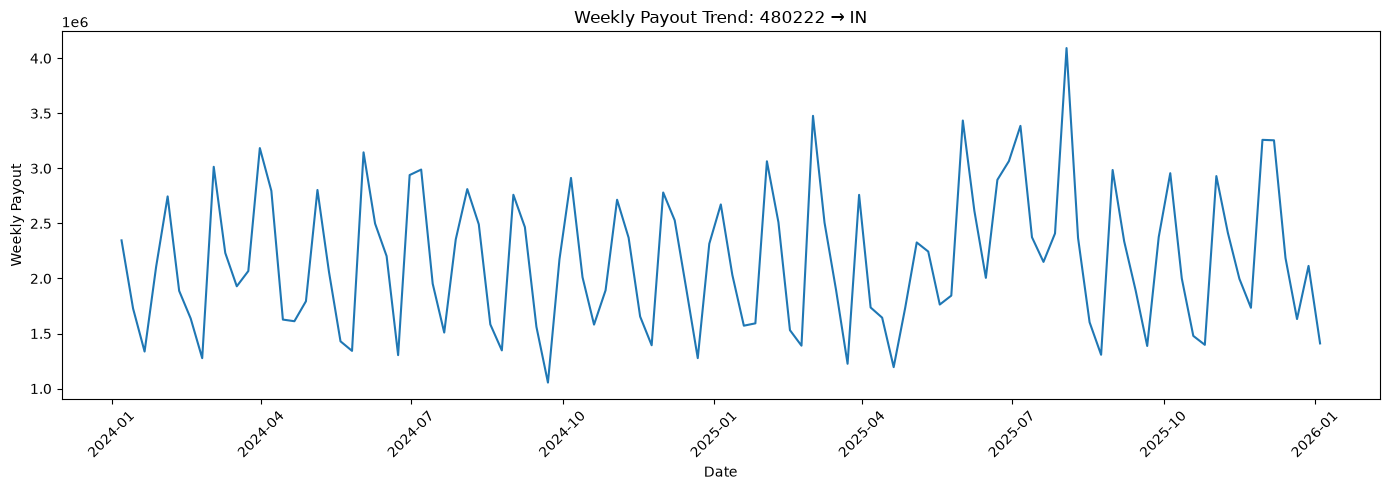

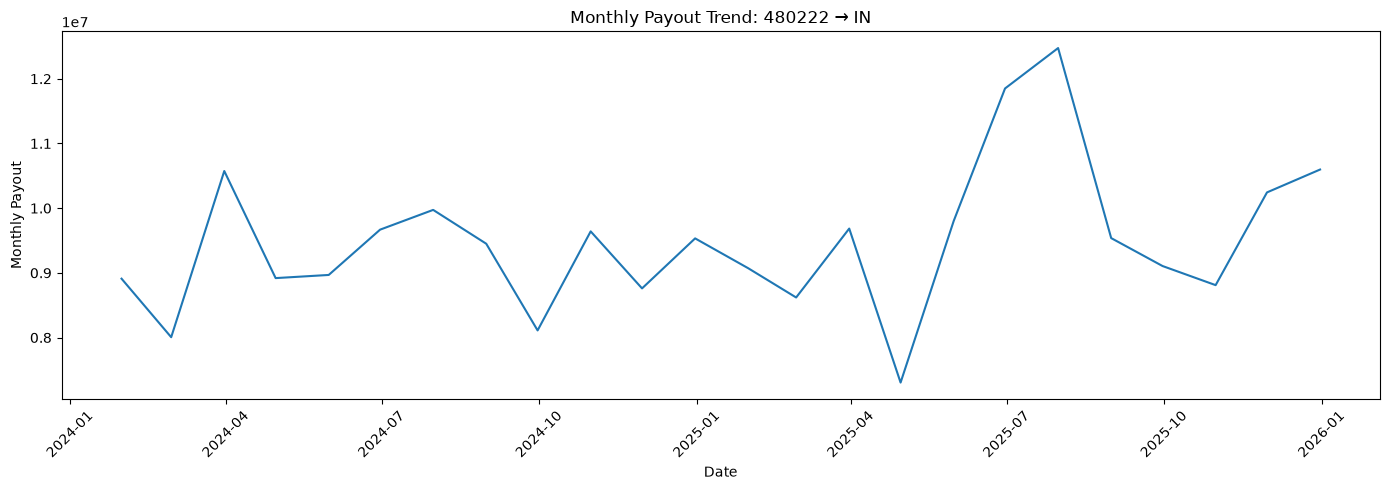

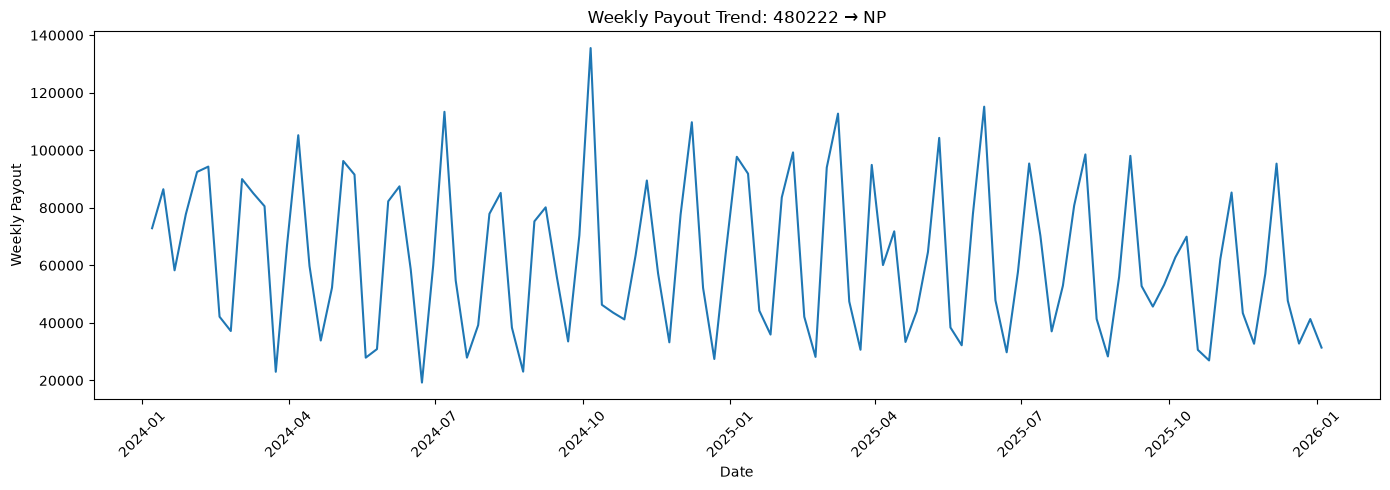

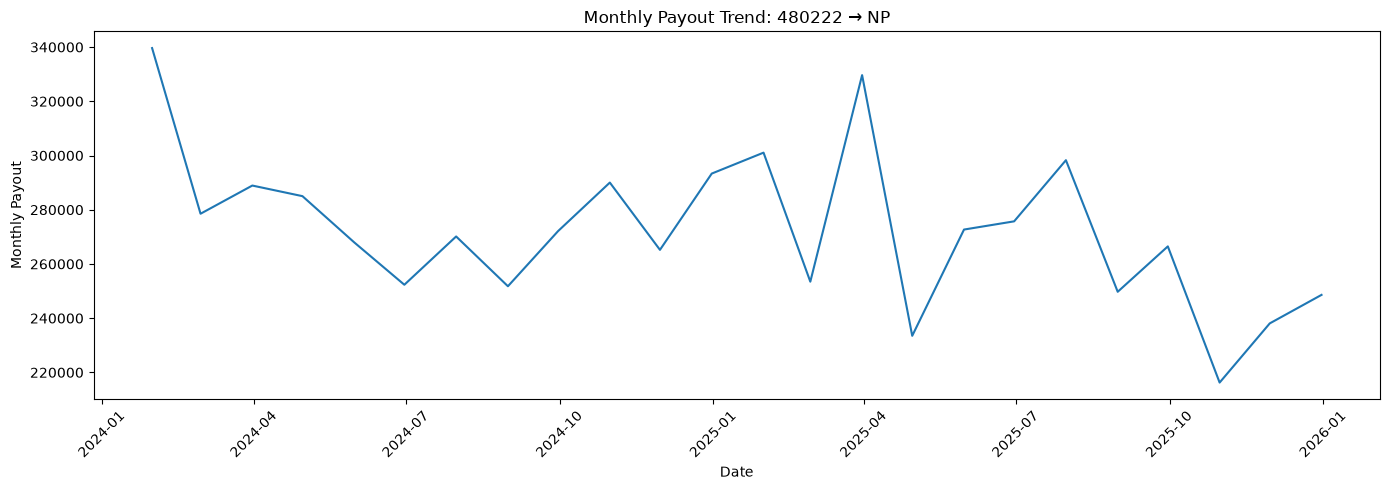

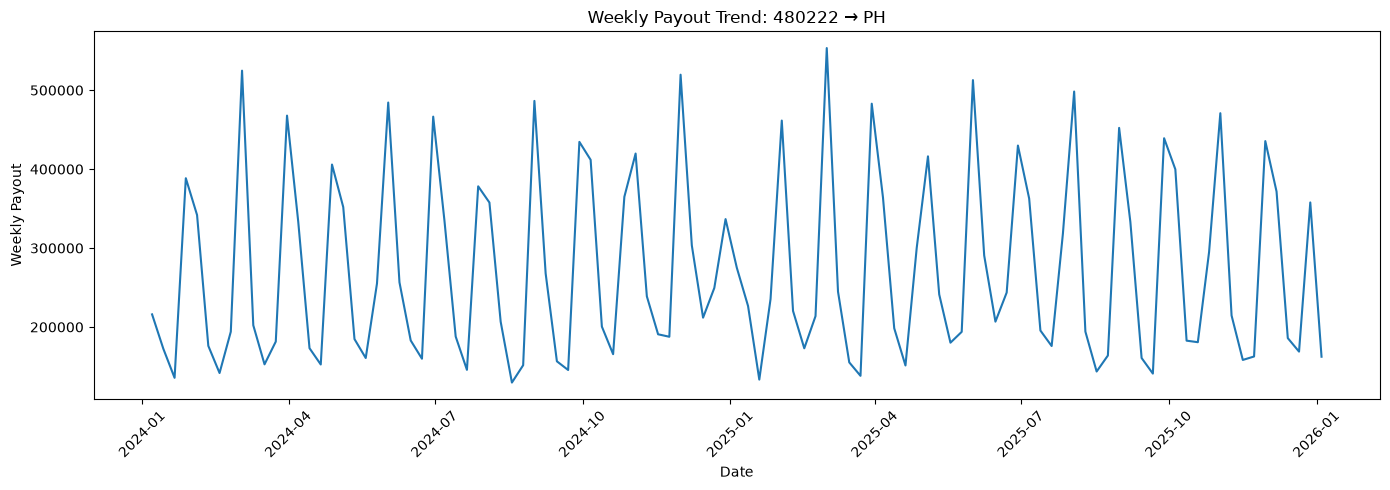

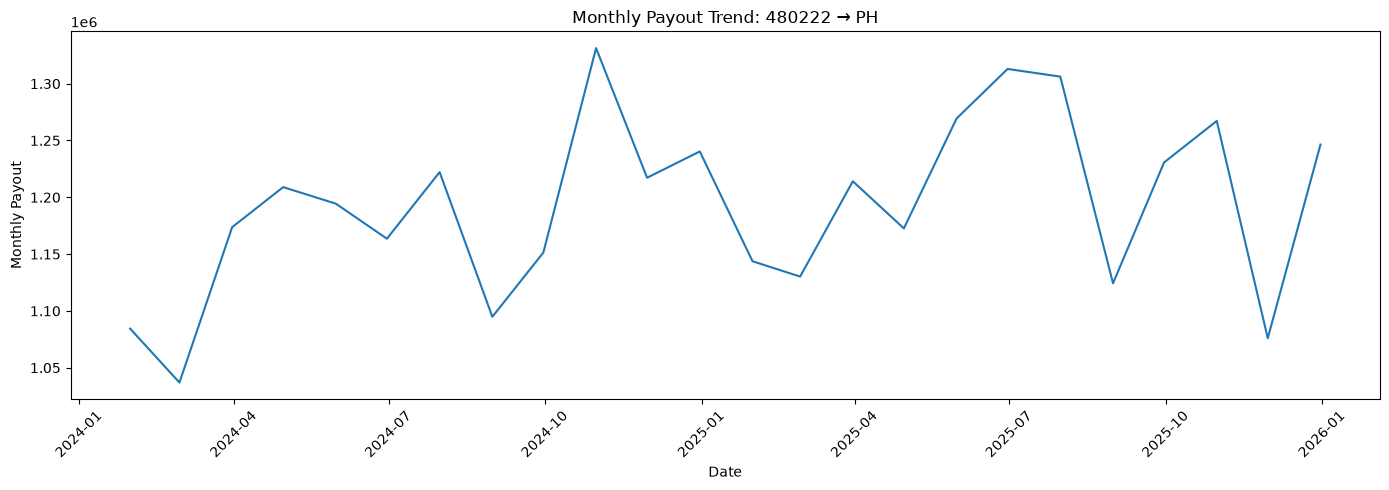

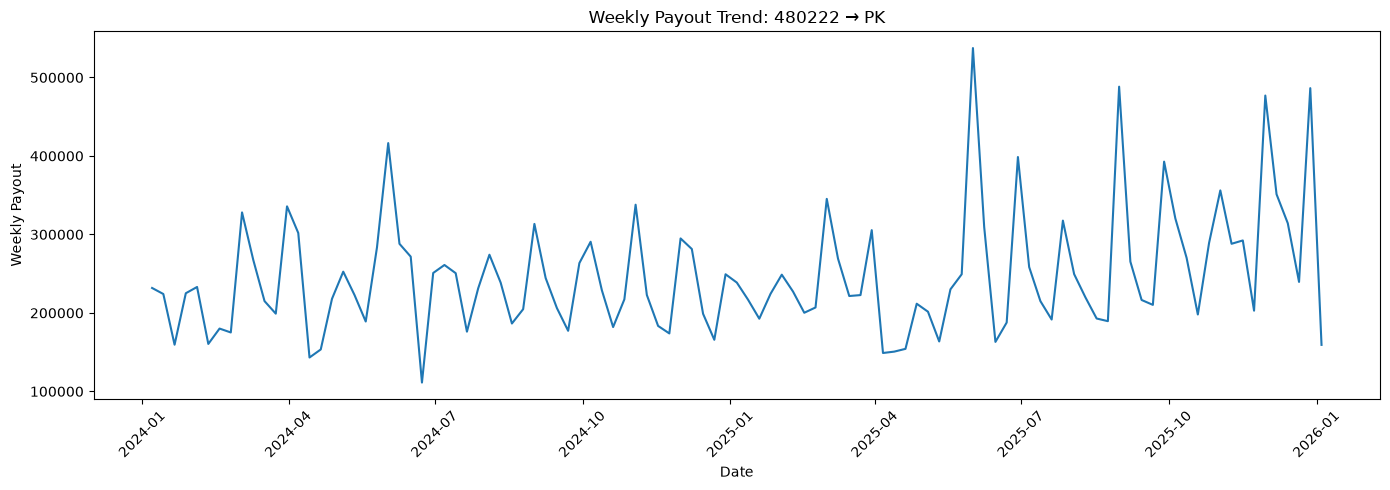

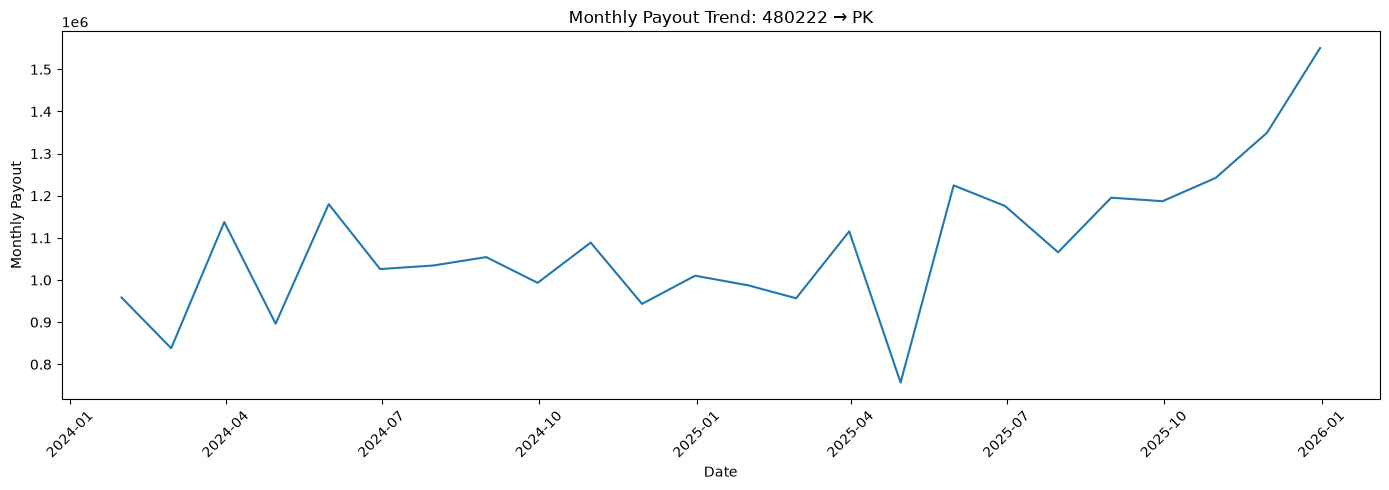

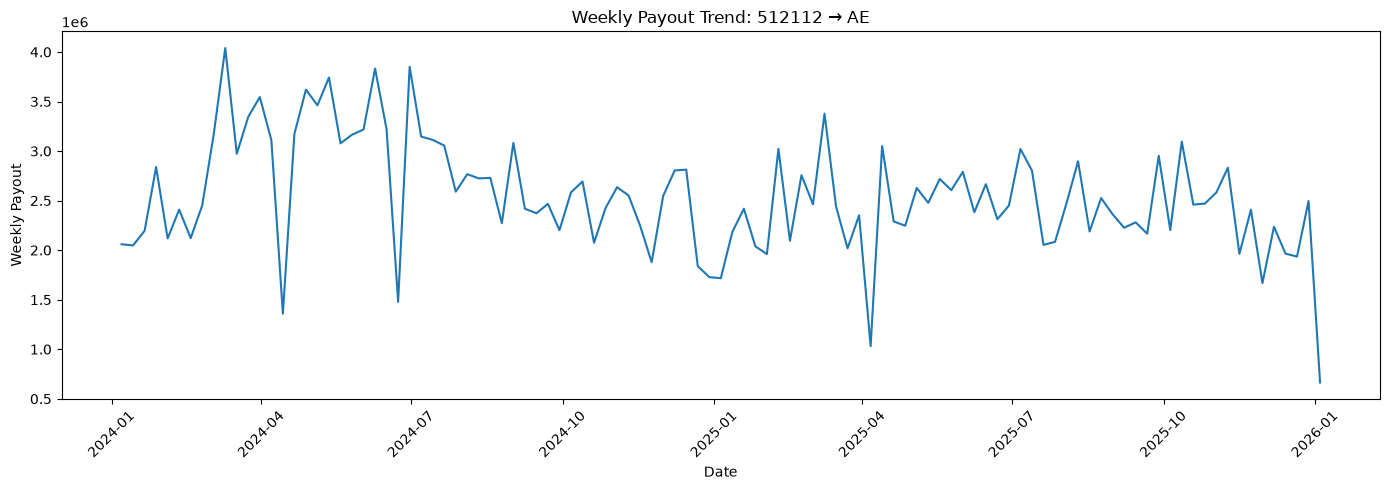

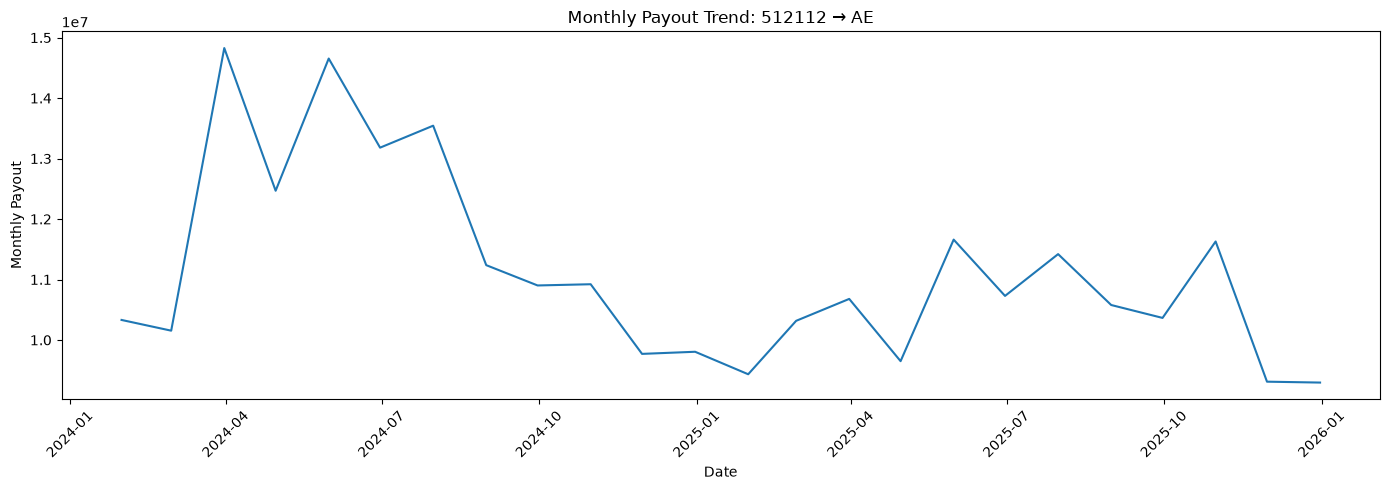

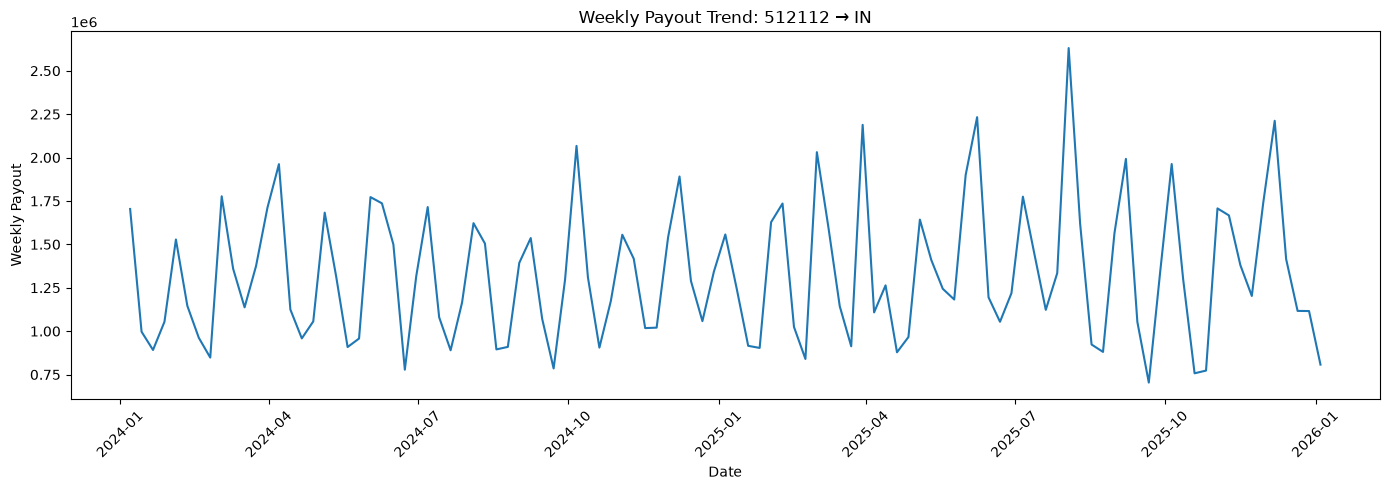

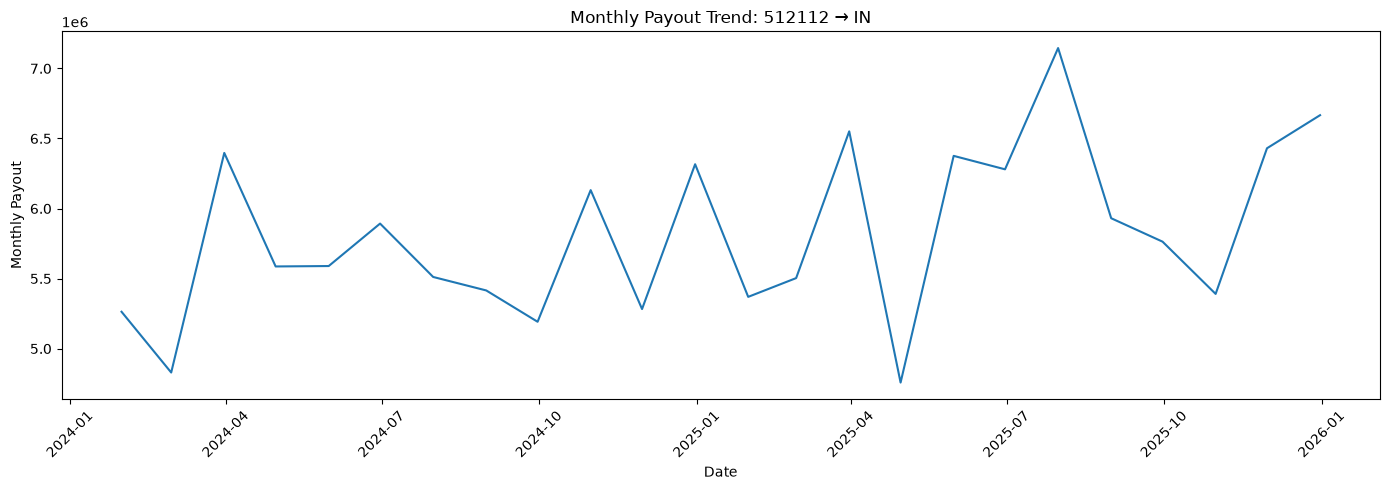

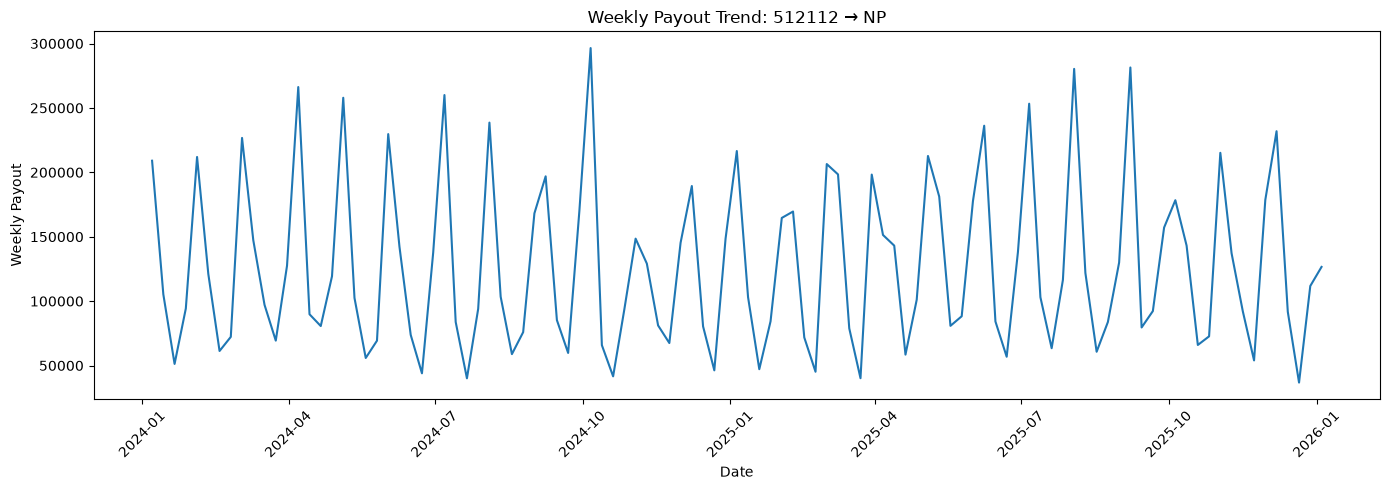

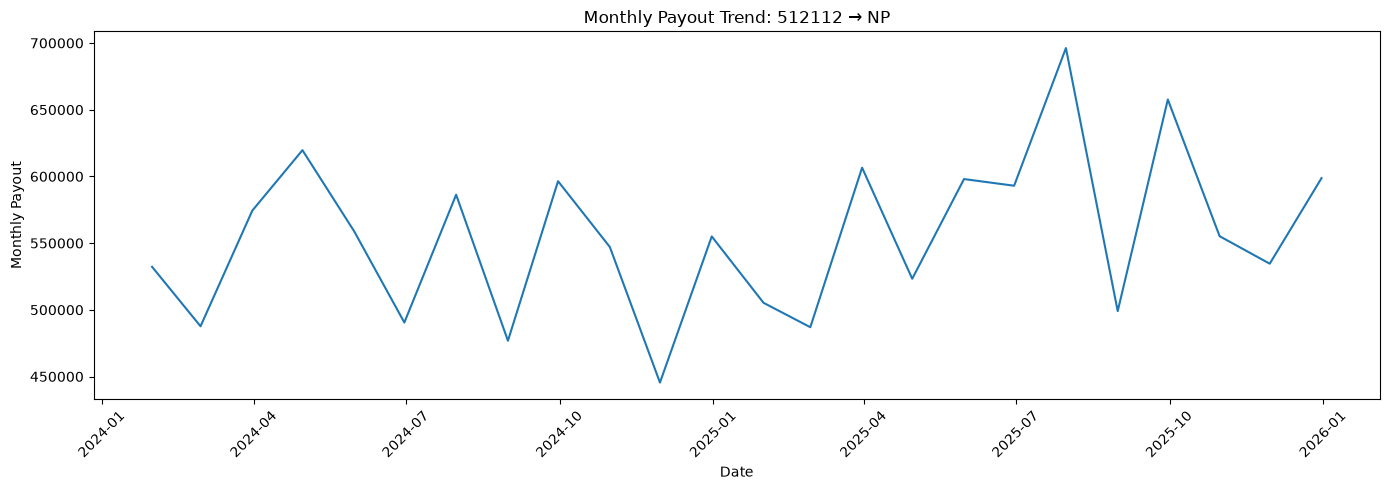

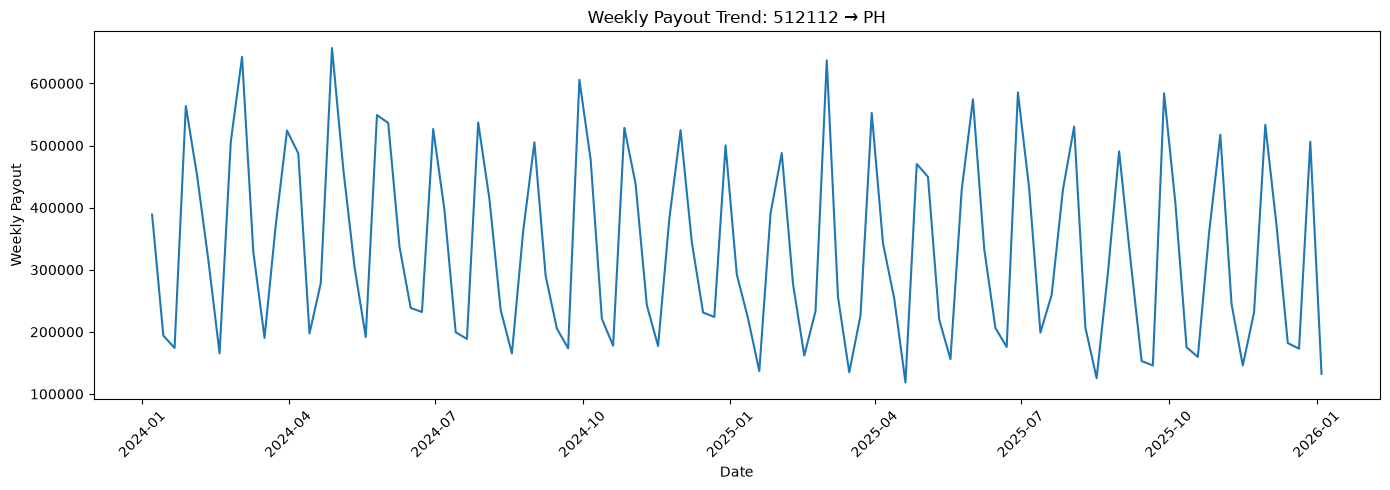

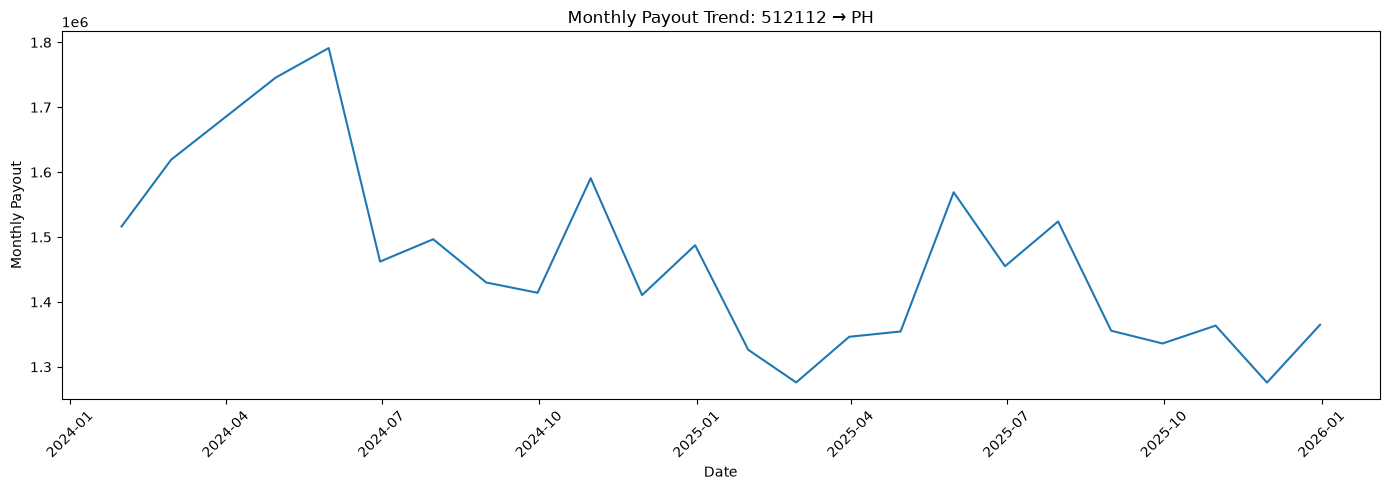

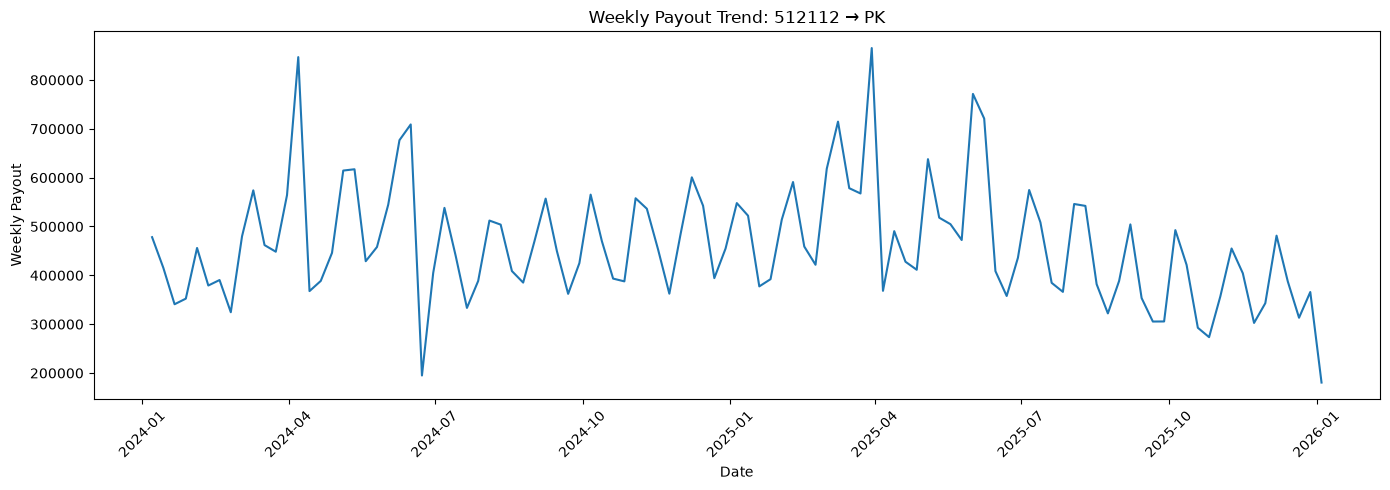

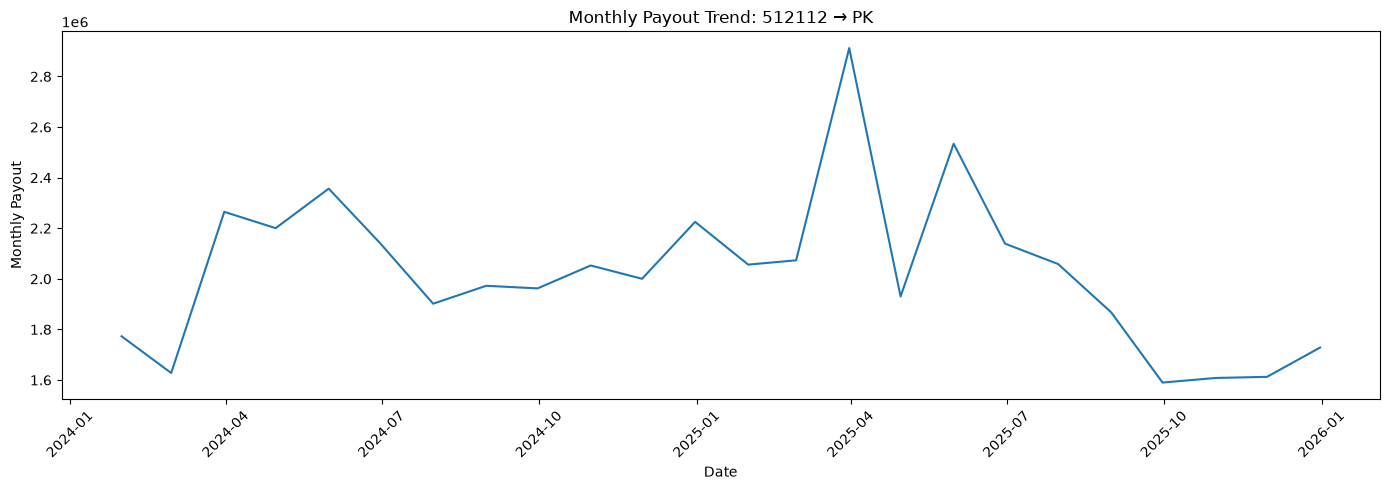

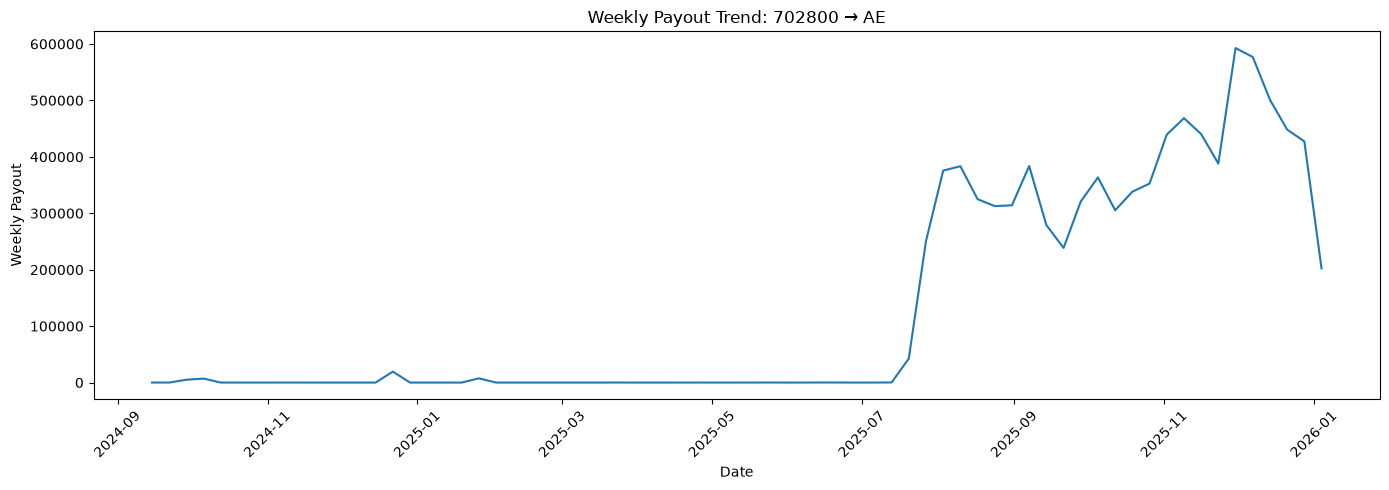

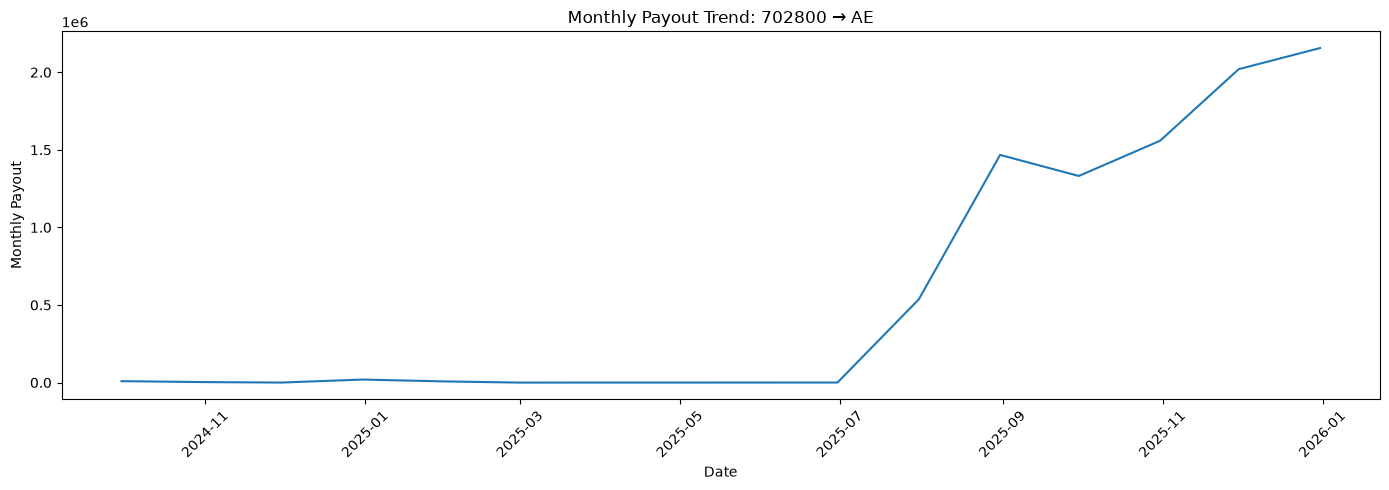

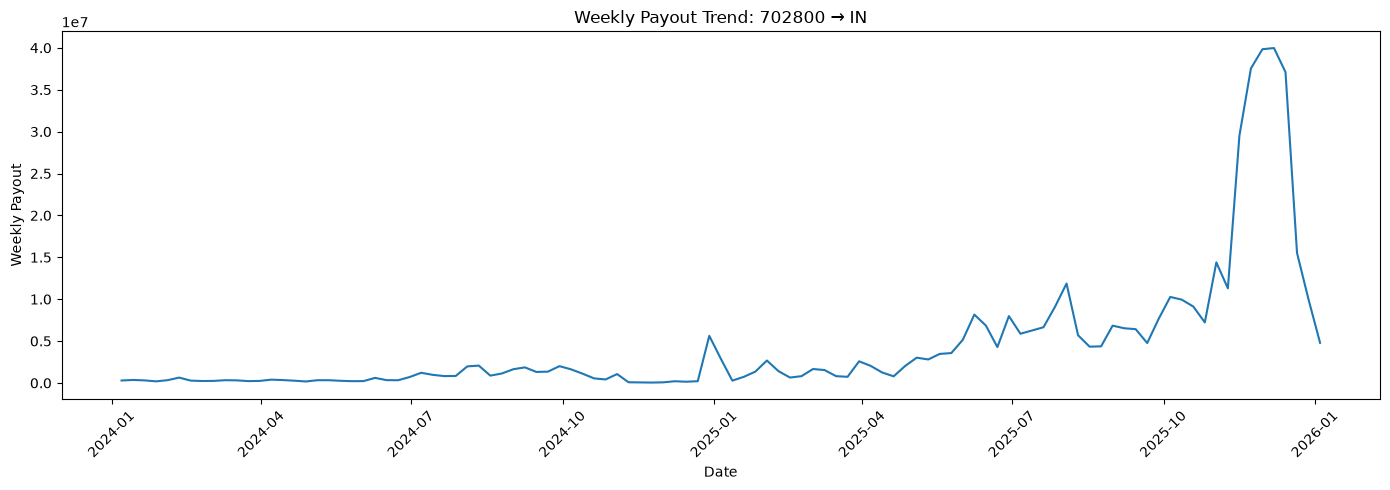

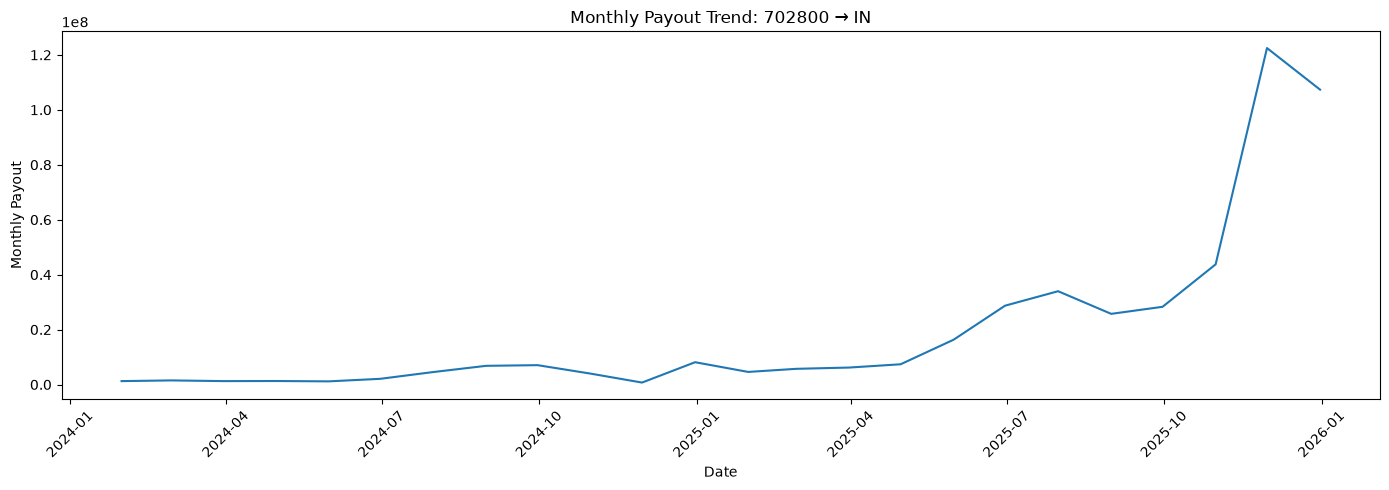

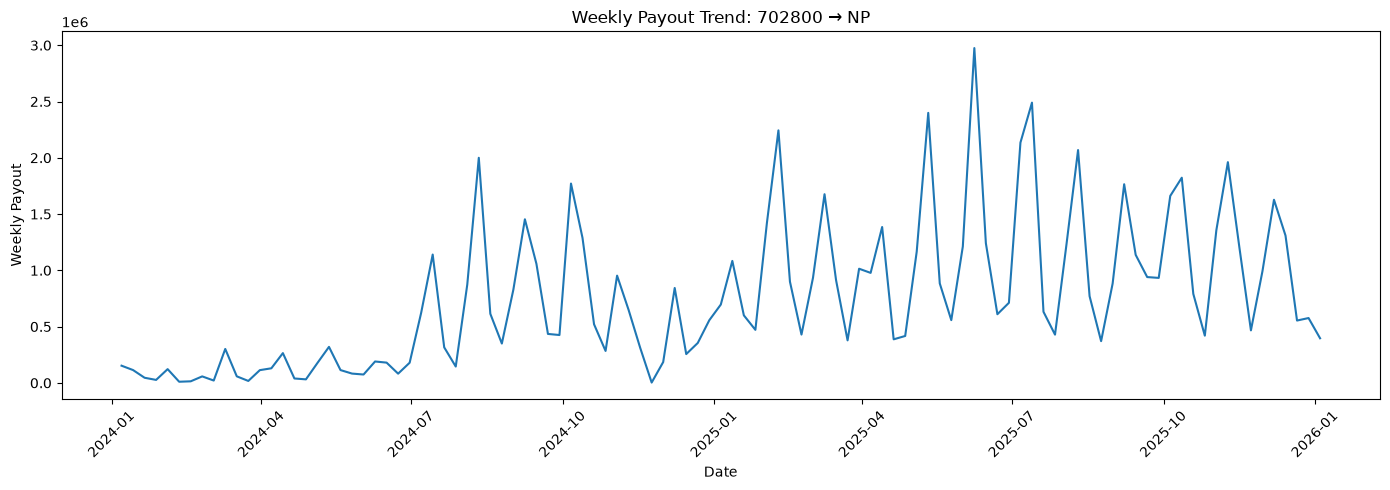

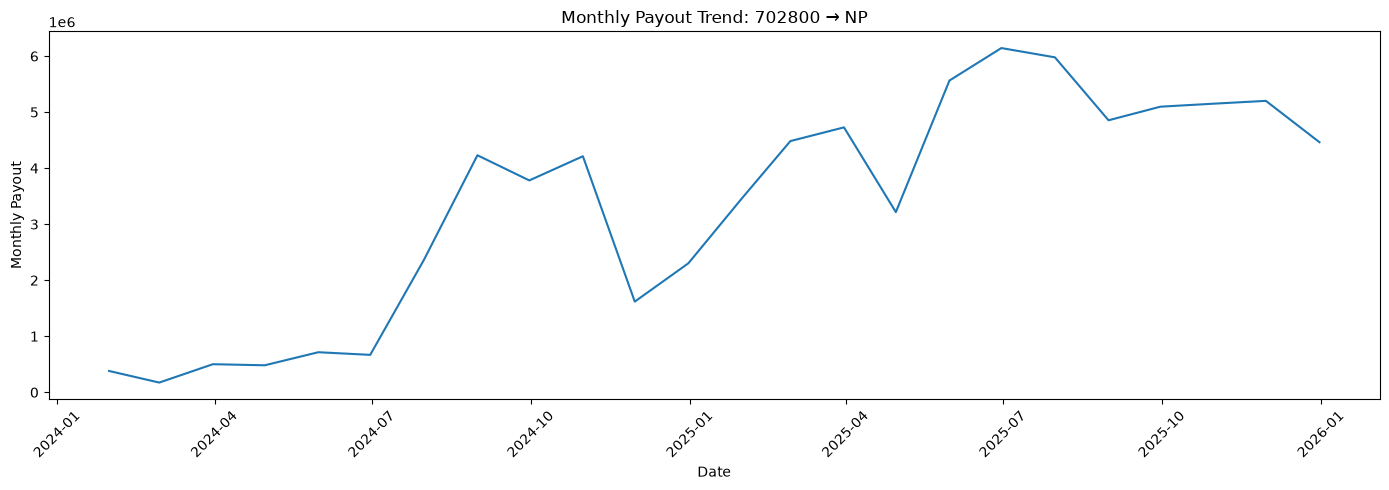

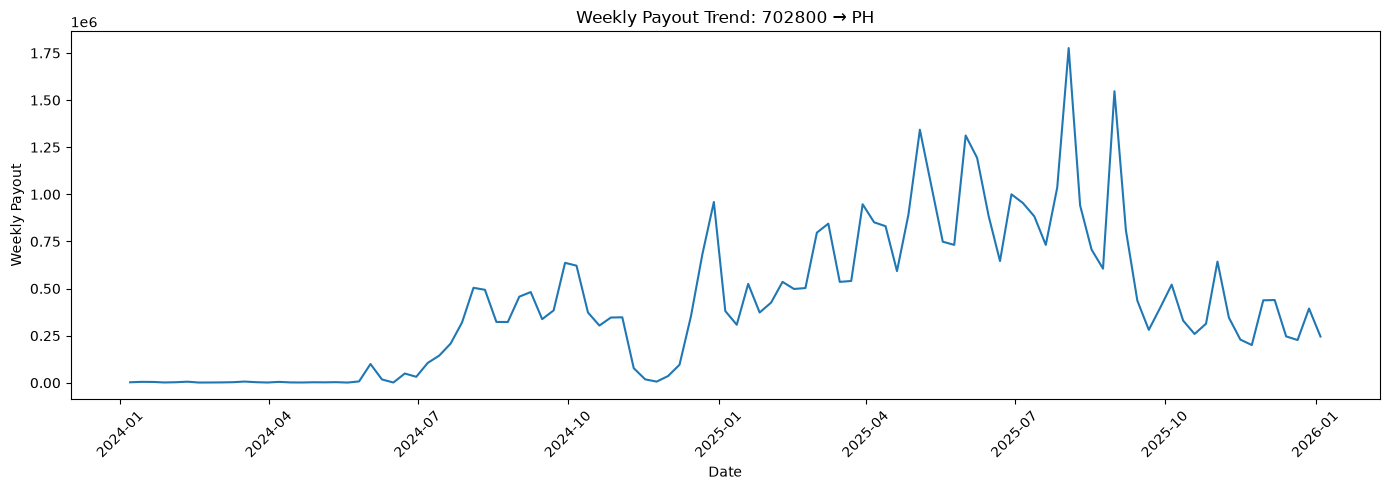

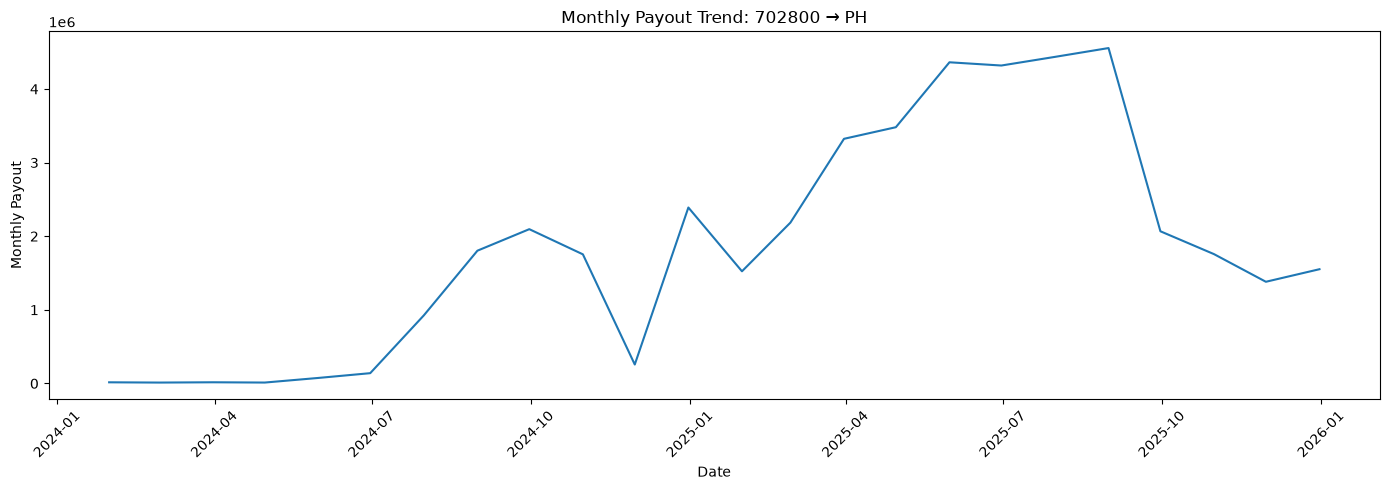

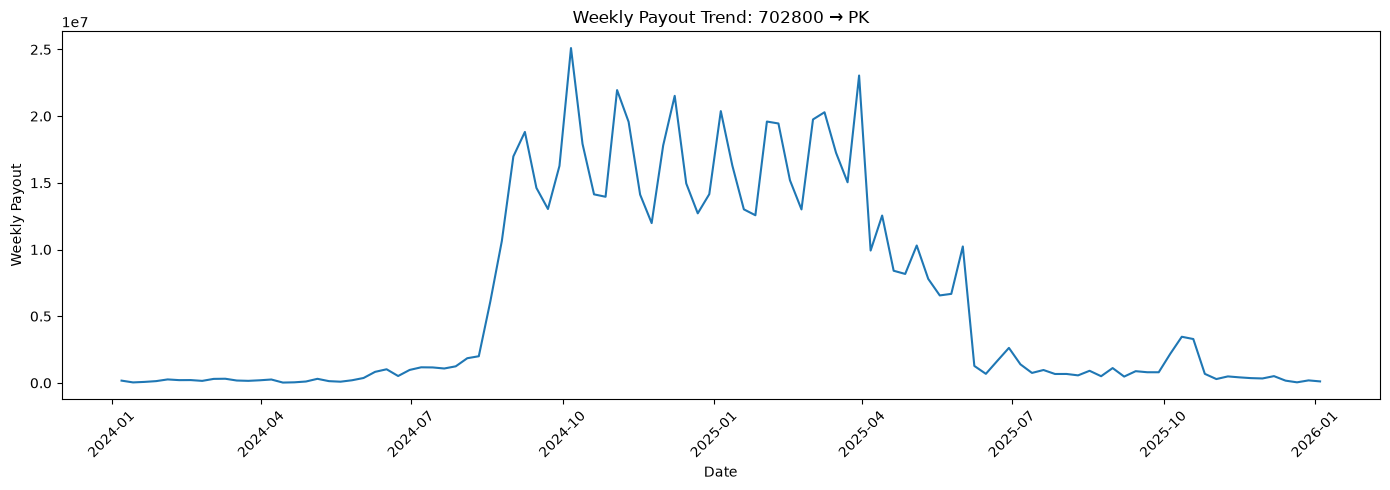

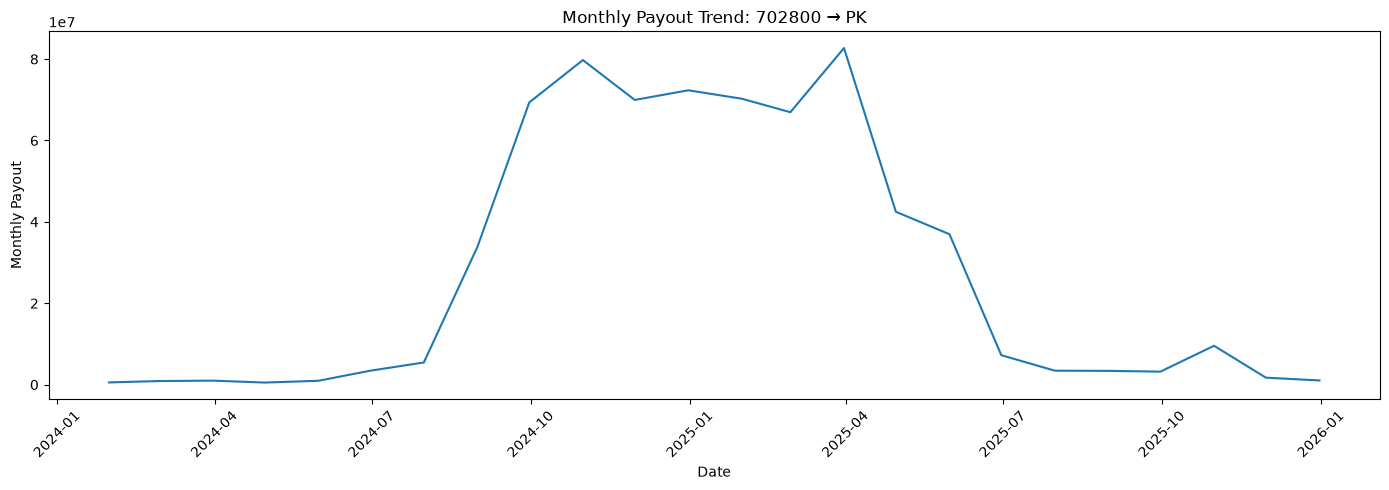

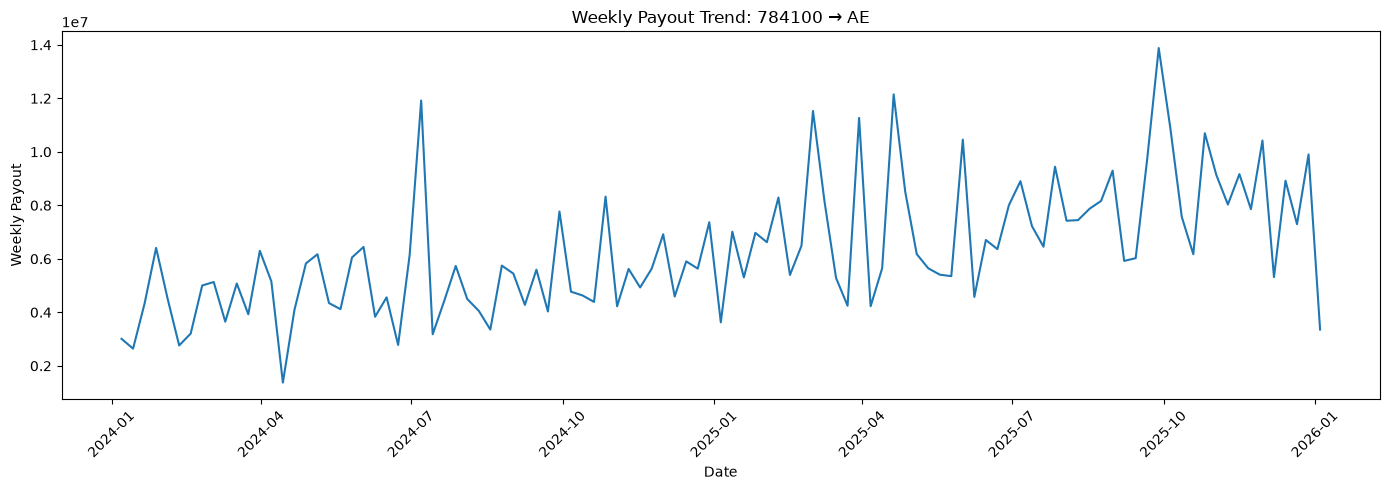

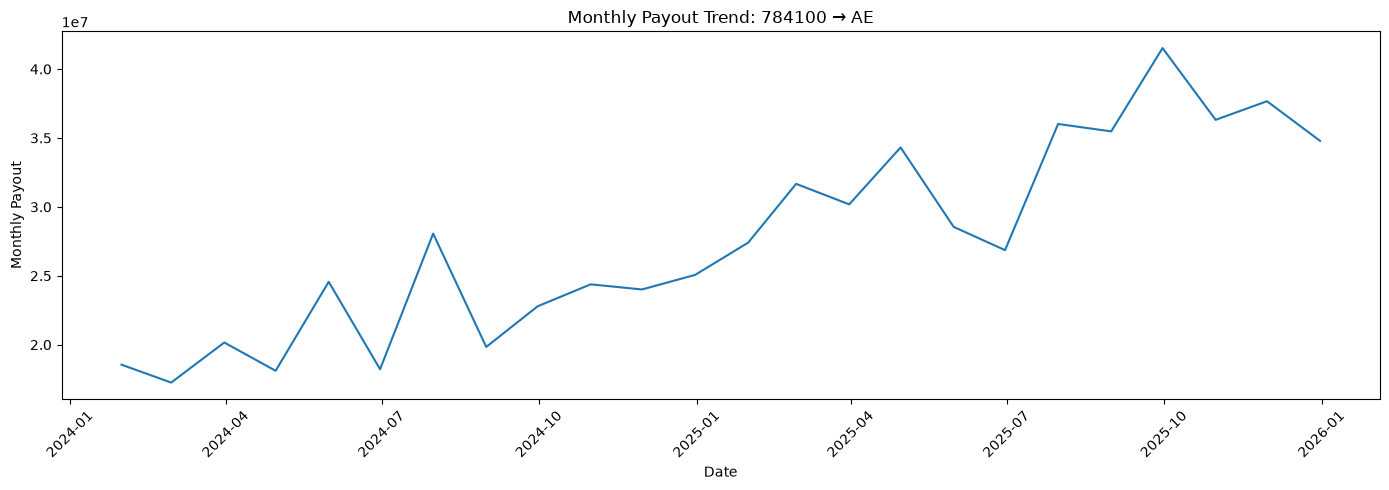

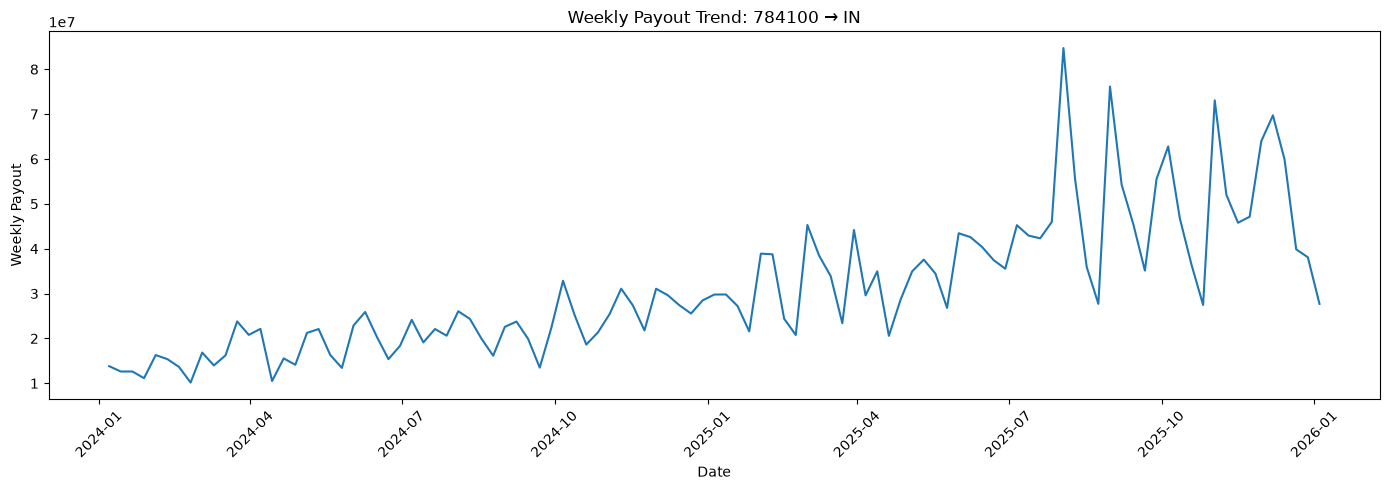

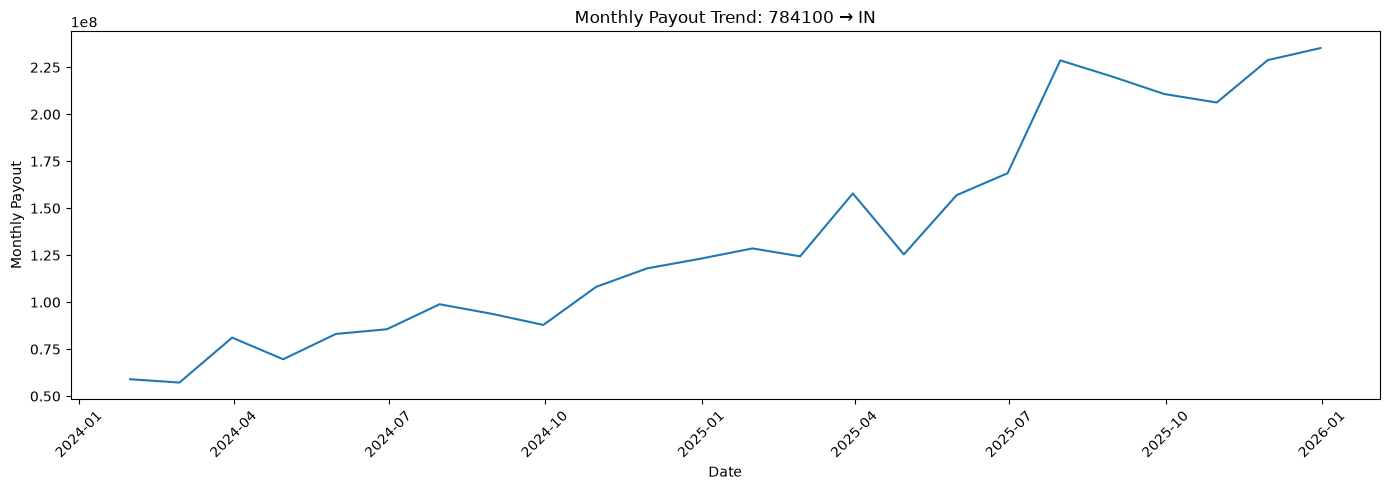

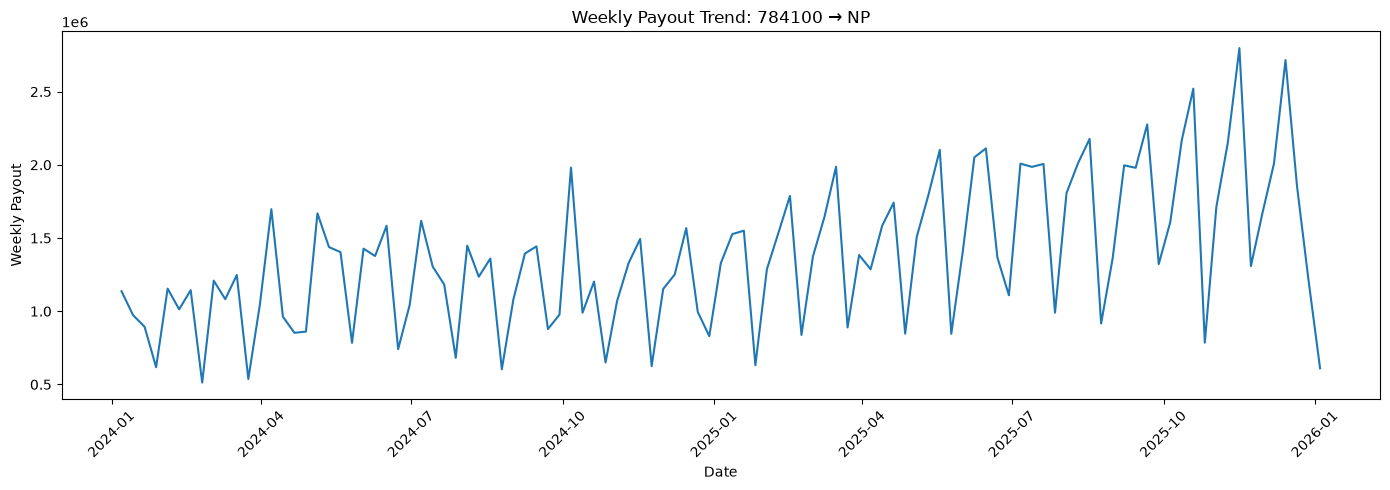

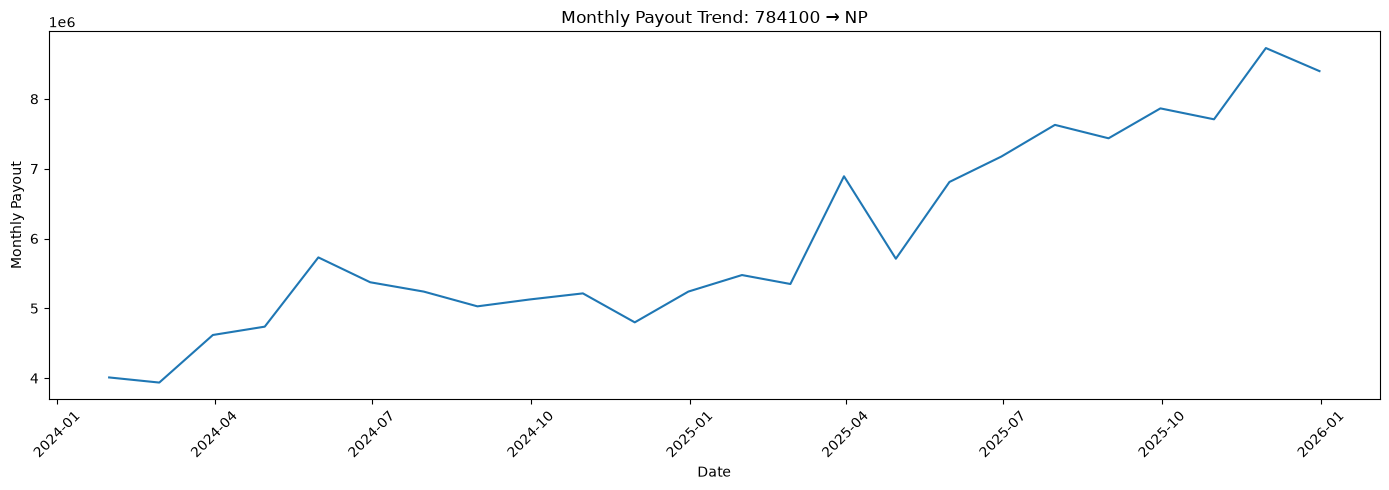

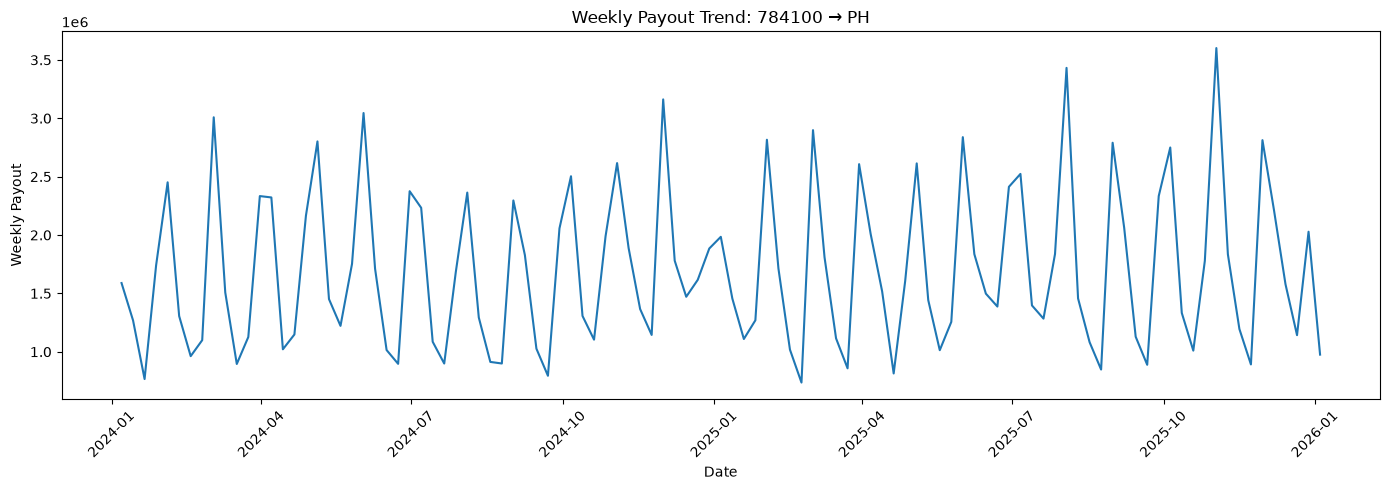

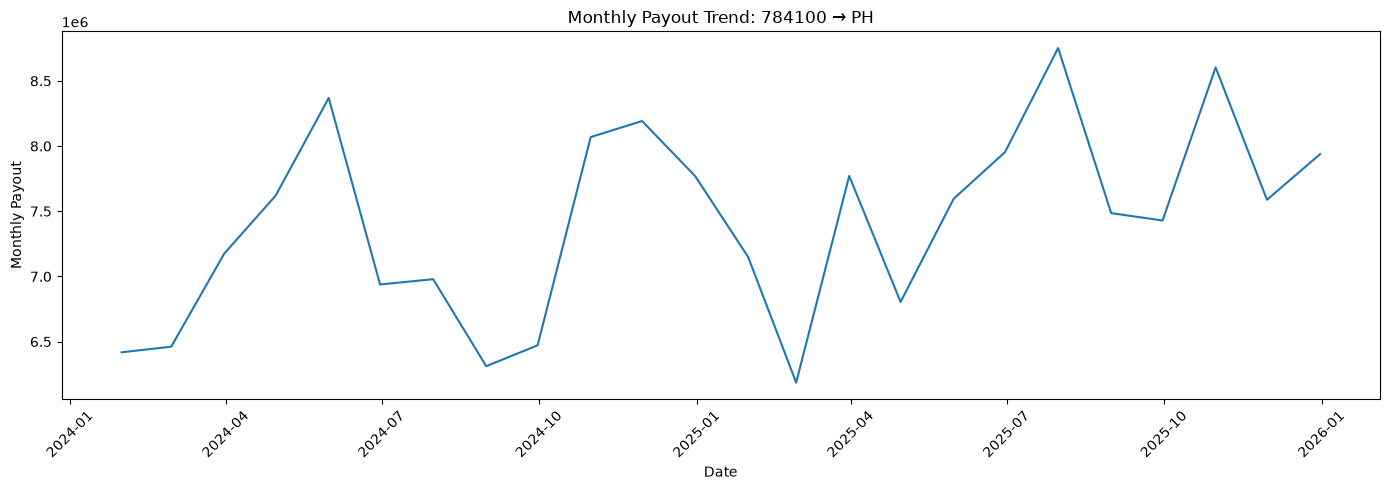

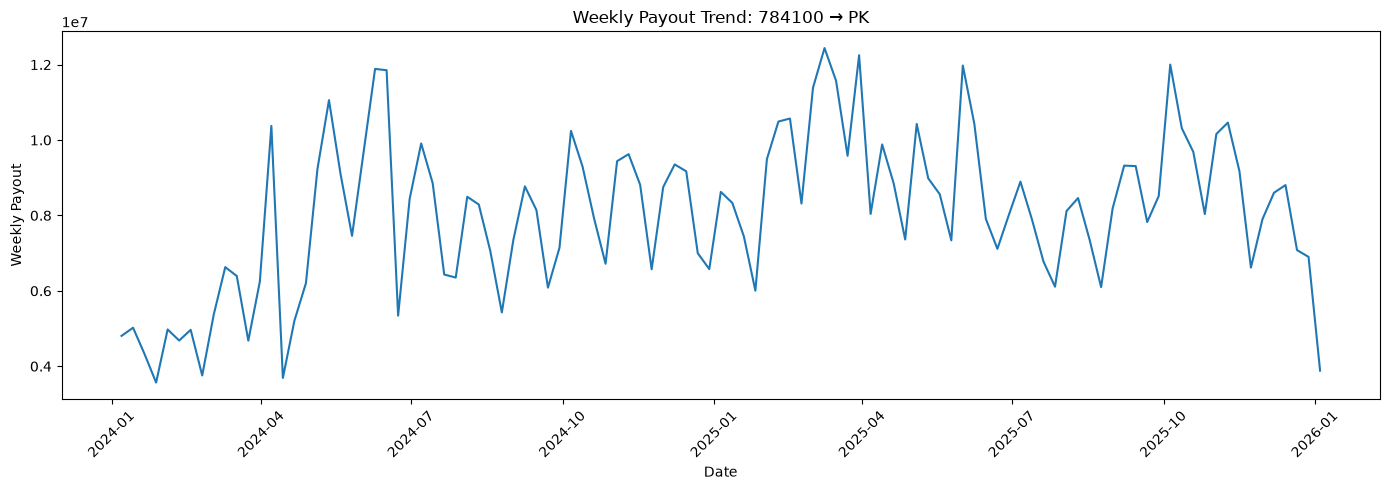

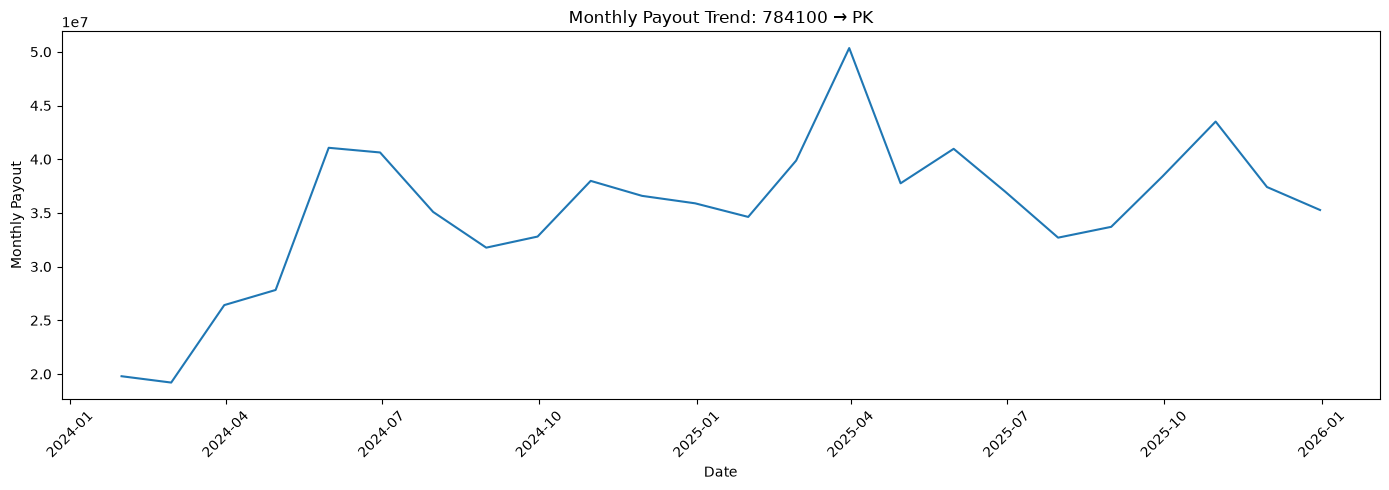

In [65]:
# Trend for the corridors
for (company, country), group in df.groupby(['Sendingagentcompanyid', 'Payoutcountrycode']):

    plot_corridor_trends(df, company, country)

## Day of week analysis

In [66]:
weekly_heatmap = (
    df.groupby(
        ['Sendingagentcompanyid',
         'Payoutcountrycode',
         'day_of_week']
    )['payOutAmtUSD']
    .mean()
    .reset_index()
)

weekly_pivot = weekly_heatmap.pivot(
    index=['Sendingagentcompanyid', 'Payoutcountrycode'],
    columns='day_of_week',
    values='payOutAmtUSD'
)

weekly_pivot.columns = [
    'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'
]

In [67]:
weekly_normalized = weekly_pivot.div(
    weekly_pivot.mean(axis=1),
    axis=0
)

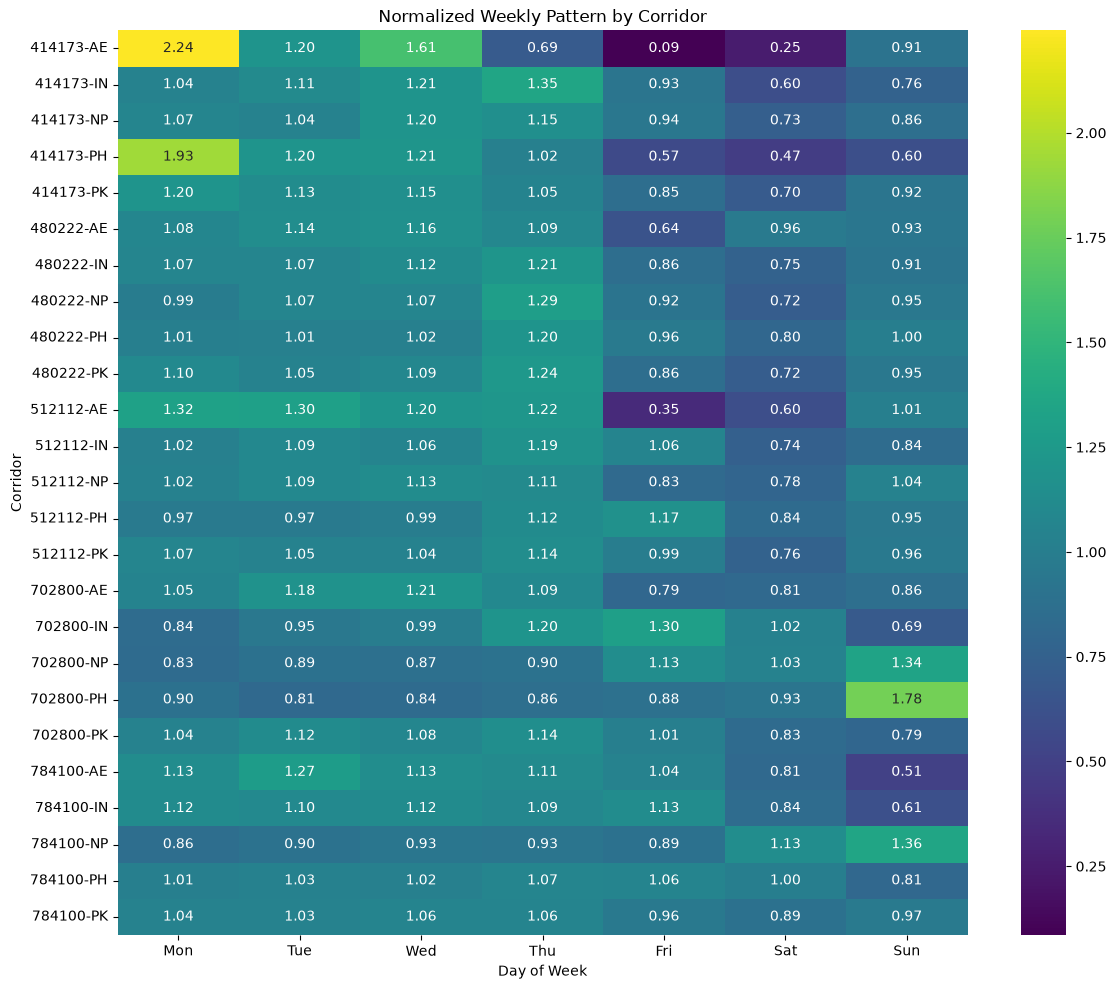

In [68]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    weekly_normalized,
    annot=True,
    fmt='.2f',
    cmap='viridis'
)

plt.title('Normalized Weekly Pattern by Corridor')
plt.xlabel('Day of Week')
plt.ylabel('Corridor')

plt.tight_layout()
plt.show()

In [69]:
df.groupby('day_of_week')['payOutAmtUSD'].agg(['count', 'mean', 'median', 'std']).sort_values('mean', ascending=False)

,count,mean,median,std
day_of_week,,,,
3,2564,500142.295411,95266.0,1.201075e+06
2,2589,496995.709695,92457.0,1.197908e+06
0,2587,493853.821089,93772.0,1.172879e+06
1,2588,492885.883809,89182.5,1.176567e+06
4,2564,455628.799662,71106.5,1.258144e+06
5,2564,365721.400511,61439.5,9.473245e+05
6,2564,333403.943962,86850.0,6.909935e+05


## Day of month analysis

In [70]:
df['day_of_month'] = df['Payindate'].dt.day
df.head()

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD,day_of_week,day_of_month
0,414173,AE,2024-01-01,31.0,29724.0,0,1
1,414173,AE,2024-01-02,250.0,55757.0,1,2
2,414173,AE,2024-01-03,155.0,-16005.0,2,3
3,414173,AE,2024-01-04,71.0,75213.0,3,4
4,414173,AE,2024-01-05,48.0,18594.0,4,5


In [71]:
monthly_heatmap = (
    df.groupby(
        ['Sendingagentcompanyid',
         'Payoutcountrycode',
         'day_of_month']
    )['payOutAmtUSD']
    .mean()
    .reset_index()
)

monthly_pivot = monthly_heatmap.pivot(
    index=['Sendingagentcompanyid', 'Payoutcountrycode'],
    columns='day_of_month',
    values='payOutAmtUSD'
)

monthly_normalized = monthly_pivot.div(
    monthly_pivot.mean(axis=1),
    axis=0
)

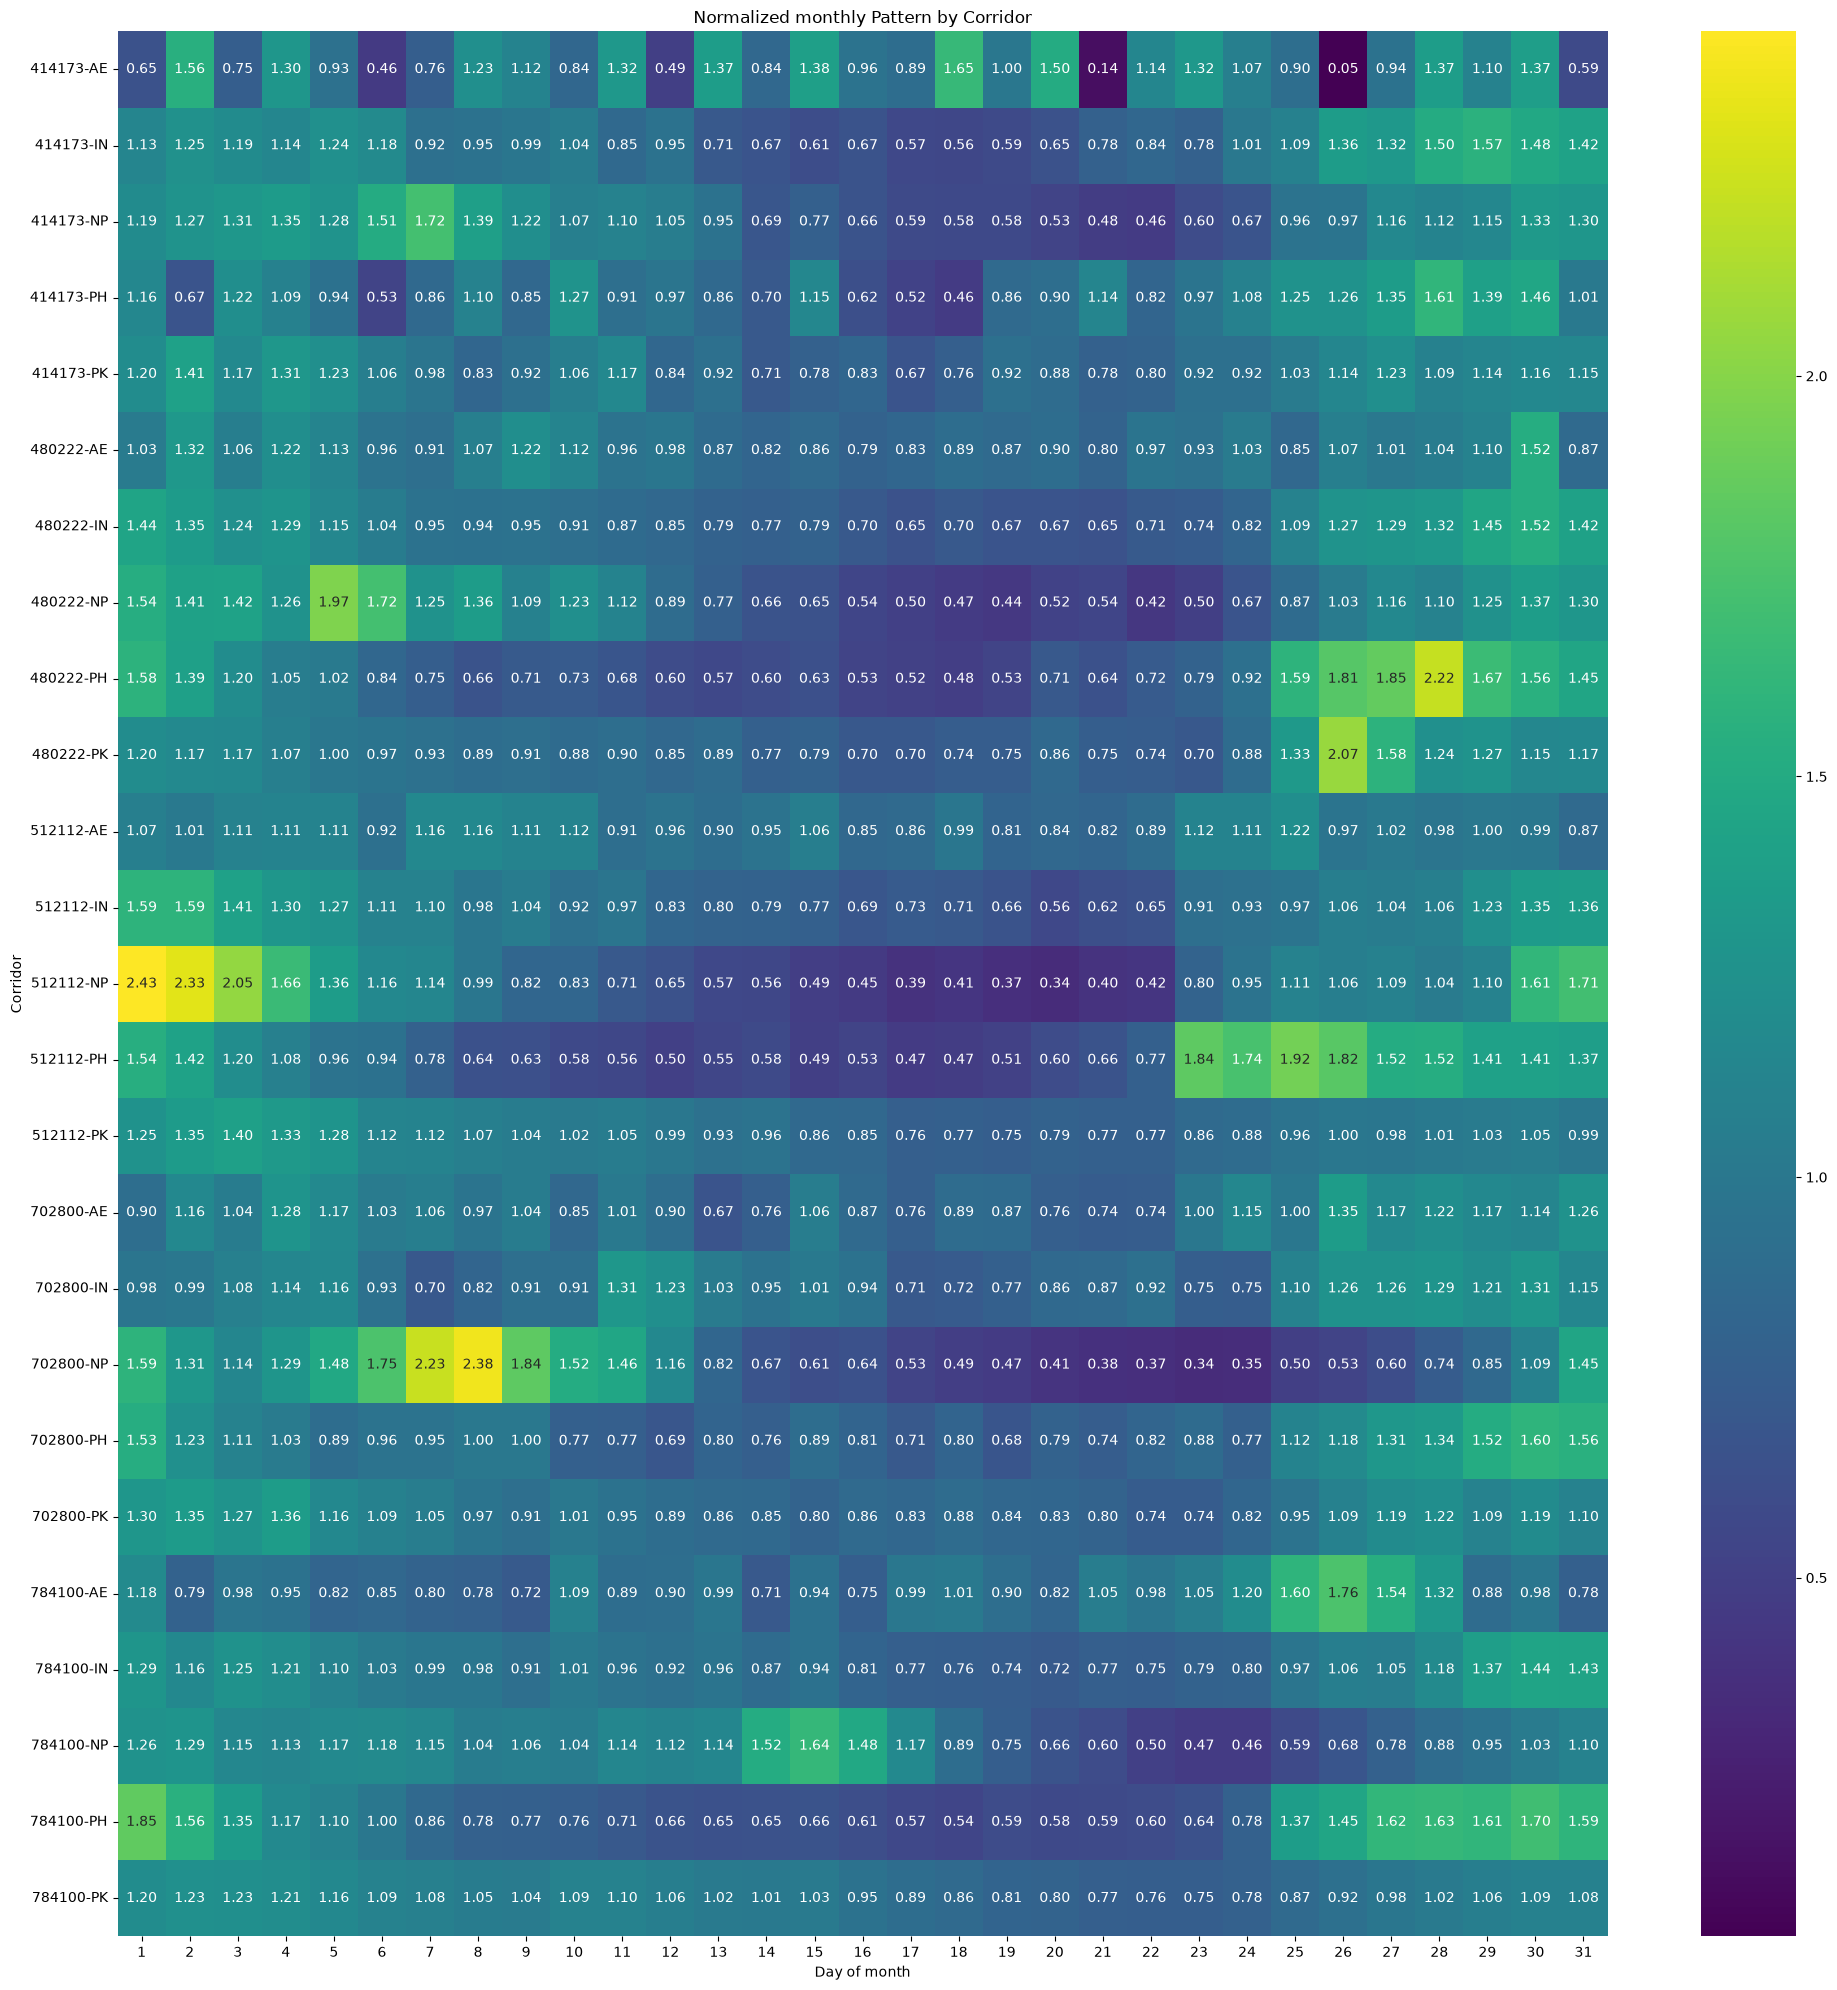

In [72]:
plt.figure(figsize=(20, 20))

sns.heatmap(
    monthly_normalized,
    annot=True,
    fmt='.2f',
    cmap='viridis'
)

plt.title('Normalized monthly Pattern by Corridor')
plt.xlabel('Day of month')
plt.ylabel('Corridor')

plt.tight_layout()
plt.show()

## Quarter

In [73]:
df['quarter'] = df['Payindate'].dt.quarter


In [74]:
df.groupby(['Payoutcountrycode','quarter'])['payOutAmtUSD'].mean()

Payoutcountrycode  quarter
AE                 1          2.944140e+05
                   2          3.048670e+05
                   3          3.398083e+05
                   4          3.244769e+05
IN                 1          9.503484e+05
                   2          1.099890e+06
                   3          1.426461e+06
                   4          1.710872e+06
NP                 1          6.147251e+04
                   2          7.030893e+04
                   3          8.317881e+04
                   4          8.319522e+04
PH                 1          9.394401e+04
                   2          1.089957e+05
                   3          1.077511e+05
                   4          1.069465e+05
PK                 1          4.810319e+05
                   2          3.739257e+05
                   3          3.746910e+05
                   4          5.272881e+05
Name: payOutAmtUSD, dtype: float64

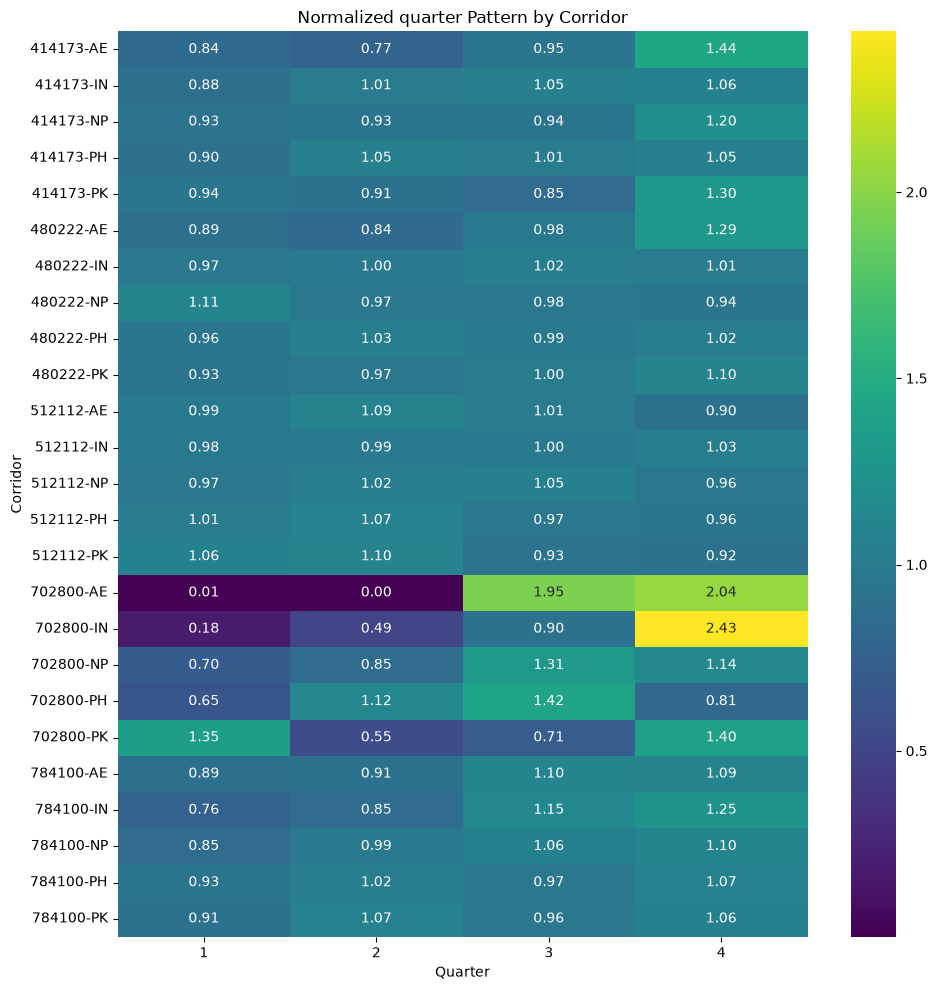

In [75]:
quarter_heatmap = (
    df.groupby(['Sendingagentcompanyid','Payoutcountrycode','quarter'])['payOutAmtUSD'].mean().reset_index()
)

quarter_pivot = quarter_heatmap.pivot(
    index=['Sendingagentcompanyid', 'Payoutcountrycode'],
    columns='quarter',
    values='payOutAmtUSD'
)

quarter_normalized = quarter_pivot.div(
    quarter_pivot.mean(axis=1),
    axis=0
)

plt.figure(figsize=(10, 10))

sns.heatmap(
    quarter_normalized,
    annot=True,
    fmt='.2f',
    cmap='viridis'
)

plt.title('Normalized quarter Pattern by Corridor')
plt.xlabel('Quarter')
plt.ylabel('Corridor')

plt.tight_layout()
plt.show()

# amount per transaction

In [76]:
df.columns

Index(['Sendingagentcompanyid', 'Payoutcountrycode', 'Payindate', 'No of Txn',
       'payOutAmtUSD', 'day_of_week', 'day_of_month', 'quarter'],
      dtype='str')

In [77]:
df['amount_per_txn'] = df.apply(lambda row: row['payOutAmtUSD'] / row['No of Txn'] if row['No of Txn'] > 0 else row['payOutAmtUSD'], axis=1)
df

,Sendingagentcompanyid,Payoutcountrycode,Payindate,No of Txn,payOutAmtUSD,day_of_week,day_of_month,quarter,amount_per_txn
0,414173,AE,2024-01-01,31.0,29724.0,0,1,1,958.838710
1,414173,AE,2024-01-02,250.0,55757.0,1,2,1,223.028000
2,414173,AE,2024-01-03,155.0,-16005.0,2,3,1,-103.258065
3,414173,AE,2024-01-04,71.0,75213.0,3,4,1,1059.338028
4,414173,AE,2024-01-05,48.0,18594.0,4,5,1,387.375000
...,...,...,...,...,...,...,...,...,...
18015,784100,PK,2025-12-27,2298.0,980494.0,5,27,4,426.672759
18016,784100,PK,2025-12-28,2624.0,1052598.0,6,28,4,401.142530
18017,784100,PK,2025-12-29,2732.0,1265657.0,0,29,4,463.271230
18018,784100,PK,2025-12-30,2819.0,1297320.0,1,30,4,460.205747
